# CMPE 260 — Project 2: Policy Gradient on Atari Pong
## Final Standalone Implementation — REINFORCE + A2C + Project 1 DQN Comparison

**Instructor:** Jahan Ghofraniha

This notebook implements and evaluates two on-policy policy-gradient approaches, **REINFORCE** and **A2C / advantage actor-critic**, on Atari Pong. The environment and preprocessing pipeline are kept consistent with Project 1 so that the completed Project 1 **DQN** results can be reused as an off-policy comparison baseline.

All reported results are taken from actual completed experiments and saved checkpoints. No target scores or missing experimental results are fabricated.

## Environment Parity with Project 1

The policy-gradient experiments use the same Atari Pong environment and preprocessing pipeline as Project 1:

- `ALE/Pong-v5`
- raw ALE `frameskip=1`
- `repeat_action_probability=0.0`
- custom max/action repeat of 4
- FIRE reset
- grayscale preprocessing
- resize and crop to 84×84
- four-frame observation stack
- scaled floating-point observations
- underlying ALE minimal action space remains six actions

For REINFORCE and A2C, the learned policy selects between the two meaningful Pong movement actions, **LEFT** and **RIGHT**, after FIRE reset. These policy actions are mapped into the unchanged ALE environment.

Project 1 DQN used the complete six-action minimal action space, so this difference is explicitly considered when comparing sample efficiency and learning behavior.

## REINFORCE Implementation

The REINFORCE implementation is based primarily on the successful Pong policy-gradient approach described by Andrej Karpathy and was then tuned experimentally in this notebook.

The final implementation uses:

- two movement actions after FIRE reset
- an 80×80 frame-difference representation derived from the Project 1 frame stack
- 6400-dimensional flattened policy input
- 200-unit ReLU hidden layer
- Bernoulli stochastic policy
- `gamma=0.99`
- Monte Carlo reward-to-go
- Pong point-boundary discount reset
- return normalization within each complete episode
- gradients summed across all frames in a complete-episode batch
- RMSProp with alpha `0.99` and epsilon `1e-5`
- tuned learning rate `2e-4`
- 10 complete Pong episodes per policy update

The final REINFORCE run used seed `777` and reached:

- **10,000,000 agent decisions**
- **18.11** mean return over the final 100 training episodes
- **18.58 ± 2.18** over 50 stochastic evaluation episodes
- approximately **4.77 hours** of measured training time

## A2C / Advantage Actor-Critic Implementation

Several conventional short-horizon Atari A2C configurations were investigated during development, including synchronous multi-environment and short n-step approaches. These versions did not learn reliably with the exact Project 1 Pong environment and preprocessing setup.

The final implementation therefore uses a **Pong-specific long-horizon advantage actor-critic formulation** built around the representation and credit-assignment structure that successfully learned with REINFORCE.

The final A2C implementation uses:

- the same LEFT/RIGHT policy action mapping as REINFORCE
- the same 80×80 frame-difference representation
- separate actor and critic networks
- 200-unit hidden layers
- complete Pong episodes for on-policy data collection
- 10 complete episodes per update
- `gamma=0.99`
- Pong point-boundary discounted returns
- a learned state-value critic \(V(s)\)
- separate actor and critic RMSProp optimizers

The actor advantage is

\[
A_t = G_t - \beta V(s_t)
\]

where \(G_t\) is the point-boundary discounted return and \(V(s_t)\) is the critic's value prediction.

The critic begins learning immediately, while its contribution to the actor is introduced gradually. The coefficient \(\beta\) begins at zero and increases toward one, allowing the early policy updates to remain close to the successful REINFORCE learning signal while the critic develops a useful value estimate.

The selected A2C configuration uses:

- actor learning rate `2e-4`
- critic learning rate `5e-4`
- RMSProp alpha `0.99`
- RMSProp epsilon `1e-5`
- 10 complete episodes per update
- baseline warmup through update `120`
- full critic contribution by update `260`
- two critic optimization epochs per actor update
- critic baseline clipping at `1.5`
- no additional entropy bonus in the final selected configuration

The final A2C run used seed `777` and reached:

- **9,050,863 agent decisions**
- **13.41** mean return over the final 100 training episodes
- **14.04 ± 3.12** over 50 stochastic evaluation episodes
- approximately **6.04 hours** of measured training time
- critic explained variance of approximately **0.72** near the end of training

The run stopped because the configured wall-clock training limit was reached before the 10-million-decision budget.

## Project 1 DQN Reference

The completed Project 1 DQN experiments are reused directly as the off-policy baseline and are not retrained in this notebook.

The three Project 1 evaluation results were:

- seed `42`: **14.72**
- seed `123`: **7.00**
- seed `2026`: **11.28**

giving an average evaluation return of approximately **11.00**.

Each DQN run used:

- **500,000 agent decisions**
- experience replay
- bootstrapped Q-learning targets
- the complete six-action Pong action space
- epsilon `0.02` during final evaluation

DQN therefore used substantially fewer environment interactions than either policy-gradient method, although its final evaluation performance varied considerably across seeds.

## Final Experimental Comparison

The measured final evaluation results are:

| Algorithm | Evaluation Return | Training Decisions | Training Time |
|---|---:|---:|---:|
| REINFORCE | **18.58 ± 2.18** | **10.00M** | **4.77 h** |
| A2C | **14.04 ± 3.12** | **9.05M** | **6.04 h** |
| DQN | **11.00 average** | **0.50M per run** | **1.20 h average** |

The experiments therefore show different strengths:

- **REINFORCE achieved the highest final evaluation performance.**
- **A2C successfully learned both a policy and a meaningful value-function baseline, but did not outperform REINFORCE in this Pong setup.**
- **DQN required far fewer environment interactions, making it substantially more sample-efficient in the measured experiments.**
- **DQN also showed greater variation across independently trained seeds.**

The notebook analyzes these differences using final evaluation performance, training-versus-evaluation behavior, learning curves over environment interactions, learning curves over wall-clock time, A2C critic learning progress, individual trained-agent results, and sample usage.

## Experimental Limitations

REINFORCE and A2C each use one completed long-run training seed, `777`, while DQN includes three independently trained Project 1 seeds: `42`, `123`, and `2026`.

Therefore, equivalent across-seed statistical confidence is **not** claimed for all three algorithms.

The evaluation standard deviations reported for REINFORCE and A2C measure variation across evaluation episodes for a single trained model. They are not equivalent to variation across independently trained seeds.

The evaluation protocols and action spaces also differ:

- REINFORCE and A2C use stochastic learned policies with two movement actions.
- DQN uses epsilon `0.02` during evaluation and the full six-action space.

These differences are disclosed when interpreting convergence, sample efficiency, and final performance.

## Important

Reinforcement-learning performance is stochastic and cannot be guaranteed for a particular seed or training run. This notebook is designed to preserve legitimate measured results, checkpoint training progress, support continuation after Colab disconnects, and compare the algorithms using the data actually produced by the experiments.

## 1. Install the Project 1 Atari stack


In [3]:
%pip install -q "gymnasium==1.2.2" "ale-py==0.11.2" "tensorboard>=2.18,<3" opencv-python-headless pandas matplotlib imageio imageio-ffmpeg


## 2. Imports, GPU check, seeds, and hardware record


In [4]:
import gc
import importlib.metadata
import json
import math
import os
import random
import time
from collections import deque
from datetime import datetime, timezone
from pathlib import Path

import ale_py
import cv2
import gymnasium as gym
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.distributions import Bernoulli, Categorical
from IPython.display import display

gym.register_envs(ale_py)

assert torch.cuda.is_available(), (
    "Select Runtime > Change runtime type > GPU before training."
)
DEVICE = torch.device("cuda")

torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False
torch.backends.cudnn.benchmark = False

FINAL_SEEDS = [42, 123, 2026]
TUNING_SEED = 777
EVAL_SEED_BASE = 90000
GAMMA = 0.99
SOLVED_MEAN100 = 19.5

def seed_everything(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def sync_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

HARDWARE = {
    "recorded_utc": datetime.now(timezone.utc).isoformat(),
    "gpu": torch.cuda.get_device_name(0),
    "gpu_memory_gib": torch.cuda.get_device_properties(0).total_memory / 1024**3,
    "pytorch": torch.__version__,
    "cuda": torch.version.cuda,
    "packages": {
        name: importlib.metadata.version(name)
        for name in ["numpy", "gymnasium", "ale-py", "pandas", "matplotlib"]
    },
}
print(json.dumps(HARDWARE, indent=2))


{
  "recorded_utc": "2026-11-13T03:40:33.100893+00:00",
  "gpu": "NVIDIA L4",
  "gpu_memory_gib": 22.0343017578125,
  "pytorch": "2.14.1+cu130",
  "cuda": "13.0",
  "packages": {
    "numpy": "2.4.6",
    "gymnasium": "1.2.2",
    "ale-py": "0.11.2",
    "pandas": "2.2.3",
    "matplotlib": "3.10.0"
  }
}


## 3. Fresh persistent Project 2 folder


In [5]:
from google.colab import drive
drive.mount("/content/drive")

ROOT = Path("/content/drive/MyDrive/CMPE260_Project2_FINAL")
RUNS = ROOT / "runs"
TABLES = ROOT / "tables"
FIGURES = ROOT / "figures"

for p in [ROOT, RUNS, TABLES, FIGURES]:
    p.mkdir(parents=True, exist_ok=True)

(ROOT / "hardware.json").write_text(json.dumps(HARDWARE, indent=2))
print("Outputs:", ROOT)


Mounted at /content/drive
Outputs: /content/drive/MyDrive/CMPE260_Project2_FINAL


## 4. Exact Project 1 Pong environment/preprocessing

This recreates the Project 1 environment:

- `ALE/Pong-v5`
- ALE `frameskip=1`
- no sticky actions
- custom max/skip = 4
- FIRE reset
- grayscale → 84×110 resize → 84×84 crop
- channel-first
- four-frame stack
- float scaling to `[0,1]`

The underlying environment still exposes six ALE Pong actions.


In [6]:
class MaxAndSkipEnv(gym.Wrapper):
    def __init__(self, env, skip=4):
        super().__init__(env)
        self._obs_buffer = deque(maxlen=2)
        self._skip = skip

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self._obs_buffer.clear()
        self._obs_buffer.append(obs)
        return obs, info

    def step(self, action):
        total_reward = 0.0
        terminated = truncated = False
        info = {}
        for _ in range(self._skip):
            obs, reward, terminated, truncated, info = self.env.step(action)
            self._obs_buffer.append(obs)
            total_reward += reward
            if terminated or truncated:
                break
        max_frame = np.max(np.stack(self._obs_buffer), axis=0)
        return max_frame, float(total_reward), terminated, truncated, info


class FireResetEnv(gym.Wrapper):
    def __init__(self, env):
        super().__init__(env)
        assert env.unwrapped.get_action_meanings()[1] == "FIRE"

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        obs, _, terminated, truncated, info = self.env.step(1)
        if terminated or truncated:
            obs, info = self.env.reset()
        obs, _, terminated, truncated, info = self.env.step(2)
        if terminated or truncated:
            obs, info = self.env.reset()
        return obs, info


class ProcessFrame84(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gym.spaces.Box(
            0, 255, (84, 84, 1), dtype=np.uint8
        )

    def observation(self, frame):
        if frame.size == 210 * 160 * 3:
            img = frame.reshape(210, 160, 3).astype(np.float32)
        elif frame.size == 250 * 160 * 3:
            img = frame.reshape(250, 160, 3).astype(np.float32)
        else:
            raise ValueError(f"Unexpected Atari frame shape: {frame.shape}")

        gray = (
            img[:, :, 0] * 0.299
            + img[:, :, 1] * 0.587
            + img[:, :, 2] * 0.114
        )
        resized = cv2.resize(gray, (84, 110), interpolation=cv2.INTER_AREA)
        return resized[18:102, :].reshape(84, 84, 1).astype(np.uint8)


class ImageToPyTorch(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gym.spaces.Box(
            0, 255, (1, 84, 84), dtype=np.uint8
        )

    def observation(self, obs):
        return np.moveaxis(obs, 2, 0)


class BufferWrapper(gym.ObservationWrapper):
    def __init__(self, env, n_steps=4):
        super().__init__(env)
        self.observation_space = gym.spaces.Box(
            0, 255, (n_steps, 84, 84), dtype=np.uint8
        )
        self.buffer = np.zeros(self.observation_space.shape, dtype=np.uint8)

    def reset(self, **kwargs):
        obs, info = self.env.reset(**kwargs)
        self.buffer.fill(0)
        return self.observation(obs), info

    def observation(self, obs):
        self.buffer[:-1] = self.buffer[1:]
        self.buffer[-1] = obs[0]
        return self.buffer.copy()


class ScaledFloatFrame(gym.ObservationWrapper):
    def __init__(self, env):
        super().__init__(env)
        self.observation_space = gym.spaces.Box(
            0.0, 1.0, (4, 84, 84), dtype=np.float32
        )

    def observation(self, obs):
        return obs.astype(np.float32) / 255.0


def make_env(seed=42, render_mode=None):
    env = gym.make(
        "ALE/Pong-v5",
        frameskip=1,
        repeat_action_probability=0.0,
        full_action_space=False,
        obs_type="rgb",
        render_mode=render_mode,
    )
    env = MaxAndSkipEnv(env, skip=4)
    env = FireResetEnv(env)
    env = ProcessFrame84(env)
    env = ImageToPyTorch(env)
    env = BufferWrapper(env, 4)
    env = ScaledFloatFrame(env)
    env.action_space.seed(seed)
    return env


## 5. Environment smoke test and policy-action mapping


In [7]:
test_env = make_env(seed=42)
obs, _ = test_env.reset(seed=42)

assert obs.shape == (4, 84, 84)
assert obs.dtype == np.float32
assert test_env.observation_space.contains(obs)
assert test_env.action_space.n == 6

ACTION_MEANINGS = list(test_env.unwrapped.get_action_meanings())
print("Pong ready:", obs.shape, obs.dtype)
print("ALE actions:", ACTION_MEANINGS)

# Canonical Pong policy-gradient implementations use only the two movement
# actions once FIRE reset has started the game. The underlying environment
# remains the same six-action ALE environment.
RIGHT_ACTION = ACTION_MEANINGS.index("RIGHT")
LEFT_ACTION = ACTION_MEANINGS.index("LEFT")
PG_ENV_ACTIONS = np.array([LEFT_ACTION, RIGHT_ACTION], dtype=np.int64)
PG_ACTION_NAMES = ["LEFT", "RIGHT"]

print("PG policy mapping:", list(enumerate(zip(PG_ENV_ACTIONS, PG_ACTION_NAMES))))
test_env.close()


Pong ready: (4, 84, 84) float32
ALE actions: ['NOOP', 'FIRE', 'RIGHT', 'LEFT', 'RIGHTFIRE', 'LEFTFIRE']
PG policy mapping: [(0, (np.int64(3), 'LEFT')), (1, (np.int64(2), 'RIGHT'))]


## 6. Shared logging/checkpoint utilities


In [8]:
EXPERIMENT_VERSION = "CMPE260_P2_RESTARTED_V1"

def save_json(path, obj):
    Path(path).write_text(json.dumps(obj, indent=2, default=float))

def moving_mean(values, window=100):
    if not values:
        return np.nan
    return float(np.mean(values[-window:]))

def config_key(cfg):
    return json.dumps(cfg, sort_keys=True, default=float)

def finite_or_nan(x):
    try:
        return float(x)
    except Exception:
        return np.nan

def load_compatible_checkpoint(path, model, optimizer, algorithm, cfg):
    path = Path(path)
    if not path.exists():
        return None

    payload = torch.load(path, map_location=DEVICE, weights_only=False)
    ok = (
        payload.get("experiment_version") == EXPERIMENT_VERSION
        and payload.get("algorithm") == algorithm
        and config_key(payload.get("config", {})) == config_key(cfg)
    )
    if not ok:
        print("Ignoring incompatible checkpoint:", path)
        return None

    model.load_state_dict(payload["model"])
    if optimizer is not None and payload.get("optimizer") is not None:
        optimizer.load_state_dict(payload["optimizer"])
    return payload


# Part A — REINFORCE

The implementation below intentionally follows the canonical Pong REINFORCE mechanics closely.

The two most important details are:

1. discounted returns are standardized **separately inside every complete Pong episode**
2. the policy-gradient loss is **summed**, not averaged over all frames, before RMSProp

Those details match the gradient accumulation in the original working `pg-pong.py`.


## 7. Canonical Pong REINFORCE policy and preprocessing


In [ ]:
REINFORCE_INPUT_SIZE = 80 * 80

def reinforce_feature(obs):
    """
    80x80 binary motion feature derived from the newest two frames of the
    existing Project-1 four-frame stack.
    """
    x = np.asarray(obs, dtype=np.float32)
    assert x.shape == (4, 84, 84)

    diff = x[-1] - x[-2]
    diff = diff[2:82, 2:82]  # 80 x 80

    out = np.zeros((80, 80), dtype=np.float32)
    out[diff > 0.02] = 1.0
    out[diff < -0.02] = -1.0
    return out.reshape(-1)


class ReinforcePolicy(nn.Module):
    """
    Two-layer policy matching the classic Pong-from-pixels structure:
    6400 -> 200 ReLU -> one Bernoulli logit.
    """
    def __init__(self, hidden_size=200):
        super().__init__()
        self.fc1 = nn.Linear(REINFORCE_INPUT_SIZE, hidden_size, bias=False)
        self.fc2 = nn.Linear(hidden_size, 1, bias=False)

        # Match the original scale closely: randn / sqrt(fan_in).
        nn.init.normal_(
            self.fc1.weight,
            mean=0.0,
            std=1.0 / math.sqrt(REINFORCE_INPUT_SIZE),
        )
        nn.init.normal_(
            self.fc2.weight,
            mean=0.0,
            std=1.0 / math.sqrt(hidden_size),
        )

    def forward(self, x):
        h = F.relu(self.fc1(x))
        return self.fc2(h).squeeze(-1)


def discount_rewards_per_episode(rewards, gamma=0.99):
    """
    Canonical Pong REINFORCE return:
    reset the running return whenever a +/-1 Pong point is observed.
    """
    rewards = np.asarray(rewards, dtype=np.float32)
    out = np.zeros_like(rewards)
    running = 0.0

    for t in range(len(rewards) - 1, -1, -1):
        if rewards[t] != 0.0:
            running = 0.0
        running = float(rewards[t]) + gamma * running
        out[t] = running

    # IMPORTANT: standardize separately inside this episode.
    out -= out.mean()
    std = out.std()
    if std > 1e-8:
        out /= std
    return out


@torch.no_grad()
def evaluate_reinforce(
    model,
    episodes=20,
    seed_base=EVAL_SEED_BASE,
    stochastic=True,
):
    was_training = model.training
    model.eval()
    returns = []

    for ep in range(episodes):
        ep_seed = int(seed_base + ep)
        seed_everything(ep_seed)
        env = make_env(seed=ep_seed)
        obs, _ = env.reset(seed=ep_seed)

        total = 0.0
        done = False

        while not done:
            feat = reinforce_feature(obs)
            x = torch.as_tensor(
                feat[None], dtype=torch.float32, device=DEVICE
            )
            logit = model(x)

            if stochastic:
                right = int(Bernoulli(logits=logit).sample().item())
            else:
                right = int((logit >= 0).item())

            env_action = int(PG_ENV_ACTIONS[right])
            obs, reward, terminated, truncated, _ = env.step(env_action)
            total += float(reward)
            done = bool(terminated or truncated)

        returns.append(total)
        env.close()

    if was_training:
        model.train()

    return {
        "episodes": int(episodes),
        "mean": float(np.mean(returns)),
        "std": float(np.std(returns, ddof=1)) if len(returns) > 1 else 0.0,
        "median": float(np.median(returns)),
        "min": float(np.min(returns)),
        "max": float(np.max(returns)),
        "returns": [float(x) for x in returns],
    }


with torch.no_grad():
    _m = ReinforcePolicy().to(DEVICE)
    _y = _m(torch.zeros(2, REINFORCE_INPUT_SIZE, device=DEVICE))
    assert _y.shape == (2,)
del _m, _y
gc.collect()
torch.cuda.empty_cache()

print("REINFORCE policy ready.")


REINFORCE policy ready.


## 8. Research-based REINFORCE trainer


In [ ]:
DEFAULT_REINFORCE_CONFIG = {
    "gamma": 0.99,
    "learning_rate": 1e-4,
    "hidden_size": 200,
    "episodes_per_update": 10,
    "rmsprop_alpha": 0.99,
    "rmsprop_eps": 1e-5,
}

def gradient_global_norm(parameters):
    sq = 0.0
    for p in parameters:
        if p.grad is not None:
            sq += float(p.grad.detach().pow(2).sum().item())
    return math.sqrt(sq)


def train_reinforce(
    seed,
    config=None,
    run_name="reinforce",
    max_steps=8_000_000,
    max_seconds=21600,
    resume=True,
    verbose_every_updates=1,
    eval_every_updates=50,
    eval_episodes=10,
    target_eval_mean=None,
):
    cfg = dict(DEFAULT_REINFORCE_CONFIG)
    if config:
        cfg.update(config)

    seed_everything(seed)

    n_envs = int(cfg["episodes_per_update"])
    run_dir = RUNS / f"{run_name}_seed{seed}"
    run_dir.mkdir(parents=True, exist_ok=True)

    checkpoint_path = run_dir / "checkpoint.pt"
    episodes_path = run_dir / "episodes.csv"
    updates_path = run_dir / "updates.csv"
    best_path = run_dir / "best_model.pt"

    model = ReinforcePolicy(int(cfg["hidden_size"])).to(DEVICE)
    optimizer = optim.RMSprop(
        model.parameters(),
        lr=float(cfg["learning_rate"]),
        alpha=float(cfg["rmsprop_alpha"]),
        eps=float(cfg["rmsprop_eps"]),
        momentum=0.0,
        centered=False,
    )

    total_steps = 0
    update_idx = 0
    episode_returns = []
    episode_rows = []
    update_rows = []
    previous_seconds = 0.0
    resume_count = 0
    best_eval = -999.0

    if resume:
        payload = load_compatible_checkpoint(
            checkpoint_path, model, optimizer, "REINFORCE", cfg
        )
        if payload is not None:
            total_steps = int(payload.get("agent_steps", 0))
            update_idx = int(payload.get("update_idx", 0))
            episode_returns = list(payload.get("episode_returns", []))
            episode_rows = list(payload.get("episode_rows", []))
            update_rows = list(payload.get("update_rows", []))
            previous_seconds = float(payload.get("train_seconds", 0.0))
            resume_count = int(payload.get("resume_count", 0)) + 1
            best_eval = float(payload.get("best_eval", -999.0))
            print(
                f"Resumed REINFORCE seed={seed} at "
                f"{total_steps:,} decisions, update={update_idx}."
            )

    sync_device()
    session_start = time.perf_counter()

    def elapsed():
        return previous_seconds + (time.perf_counter() - session_start)

    status = "budget_exhausted"

    while total_steps < max_steps and elapsed() < max_seconds:
        # Freeze the current policy while collecting exactly n_envs full episodes.
        envs = [
            make_env(seed=seed + 10_000 * i + 1_000_000 * (resume_count + update_idx))
            for i in range(n_envs)
        ]
        observations = []
        for i, env in enumerate(envs):
            o, _ = env.reset(
                seed=seed + 10_000 * i + 1_000_000 * (resume_count + update_idx)
            )
            observations.append(o)

        active = np.ones(n_envs, dtype=bool)
        states = [[] for _ in range(n_envs)]
        actions = [[] for _ in range(n_envs)]
        rewards = [[] for _ in range(n_envs)]
        scores = np.zeros(n_envs, dtype=np.float32)
        lengths = np.zeros(n_envs, dtype=np.int64)

        model.eval()
        budget_hit = False

        while active.any():
            if total_steps >= max_steps or elapsed() >= max_seconds:
                budget_hit = True
                break

            ids = np.flatnonzero(active)
            feats = np.stack([reinforce_feature(observations[i]) for i in ids])
            x = torch.as_tensor(feats, dtype=torch.float32, device=DEVICE)

            with torch.no_grad():
                logits = model(x)
                sampled = Bernoulli(logits=logits).sample().cpu().numpy().astype(np.int64)

            for j, env_i in enumerate(ids):
                a = int(sampled[j])
                env_action = int(PG_ENV_ACTIONS[a])

                states[env_i].append(feats[j].astype(np.int8))
                actions[env_i].append(a)

                o2, r, terminated, truncated, _ = envs[env_i].step(env_action)
                r = float(r)

                rewards[env_i].append(r)
                scores[env_i] += r
                lengths[env_i] += 1
                observations[env_i] = o2
                total_steps += 1

                if terminated or truncated:
                    active[env_i] = False

                if total_steps >= max_steps or elapsed() >= max_seconds:
                    budget_hit = True
                    break

        for env in envs:
            env.close()

        # Never mix partial episodes into REINFORCE.
        if active.any():
            print(
                "Budget boundary reached inside an episode batch; "
                "discarding partial episodes and retaining the last checkpoint."
            )
            break

        # Prepare one canonical batch. Returns are normalized PER EPISODE.
        batch_states = []
        batch_actions = []
        batch_advantages = []

        for i in range(n_envs):
            adv_i = discount_rewards_per_episode(
                rewards[i], gamma=float(cfg["gamma"])
            )
            batch_states.append(np.stack(states[i]))
            batch_actions.append(np.asarray(actions[i], dtype=np.float32))
            batch_advantages.append(adv_i.astype(np.float32))

            episode_returns.append(float(scores[i]))
            mean100 = moving_mean(episode_returns, 100)
            episode_rows.append({
                "episode": len(episode_returns),
                "agent_steps": int(total_steps),
                "train_seconds": float(elapsed()),
                "reward": float(scores[i]),
                "mean100": float(mean100),
                "full100": len(episode_returns) >= 100,
                "episode_length": int(lengths[i]),
            })

        X = np.concatenate(batch_states, axis=0)
        A = np.concatenate(batch_actions, axis=0)
        ADV = np.concatenate(batch_advantages, axis=0)

        # Canonical gradient accumulation:
        # sum policy-gradient contributions across timesteps/episodes.
        model.train()
        optimizer.zero_grad(set_to_none=True)

        chunk = 4096
        policy_objective_sum = 0.0
        entropy_weighted = 0.0
        B = len(A)

        for start in range(0, B, chunk):
            end = min(start + chunk, B)
            x = torch.as_tensor(
                X[start:end], dtype=torch.float32, device=DEVICE
            )
            a = torch.as_tensor(
                A[start:end], dtype=torch.float32, device=DEVICE
            )
            adv = torch.as_tensor(
                ADV[start:end], dtype=torch.float32, device=DEVICE
            )

            logits = model(x)
            dist = Bernoulli(logits=logits)
            logp = dist.log_prob(a)

            # IMPORTANT: SUM, not mean.
            loss = -(logp * adv).sum()
            loss.backward()

            policy_objective_sum += float((-loss).detach().item())
            entropy_weighted += (
                float(dist.entropy().mean().detach().item())
                * (end - start) / B
            )

        grad_norm = gradient_global_norm(model.parameters())

        if not math.isfinite(grad_norm):
            raise RuntimeError("Non-finite REINFORCE gradient detected.")

        optimizer.step()
        update_idx += 1

        evaluation = None
        if eval_every_updates and update_idx % int(eval_every_updates) == 0:
            evaluation = evaluate_reinforce(
                model,
                episodes=int(eval_episodes),
                seed_base=200_000 + update_idx * 100,
                stochastic=True,
            )
            if evaluation["mean"] > best_eval:
                best_eval = float(evaluation["mean"])
                torch.save(model.state_dict(), best_path)

        row = {
            "update": int(update_idx),
            "agent_steps": int(total_steps),
            "episodes": int(len(episode_returns)),
            "train_seconds": float(elapsed()),
            "mean100": moving_mean(episode_returns, 100),
            "gradient_norm": float(grad_norm),
            "policy_objective_sum": float(policy_objective_sum),
            "entropy": float(entropy_weighted),
            "best_eval": float(best_eval),
        }
        if evaluation is not None:
            row["eval_mean"] = evaluation["mean"]
            row["eval_std"] = evaluation["std"]

        update_rows.append(row)

        pd.DataFrame(episode_rows).to_csv(episodes_path, index=False)
        pd.DataFrame(update_rows).to_csv(updates_path, index=False)

        torch.save({
            "experiment_version": EXPERIMENT_VERSION,
            "algorithm": "REINFORCE",
            "seed": int(seed),
            "config": cfg,
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "agent_steps": int(total_steps),
            "episode_returns": episode_returns,
            "episode_rows": episode_rows,
            "update_rows": update_rows,
            "update_idx": int(update_idx),
            "train_seconds": float(elapsed()),
            "resume_count": int(resume_count),
            "best_eval": float(best_eval),
        }, checkpoint_path)

        if update_idx % int(verbose_every_updates) == 0:
            msg = (
                f"REINFORCE seed={seed} "
                f"upd={update_idx:4d} "
                f"eps={len(episode_returns):5d} "
                f"steps={total_steps:9,d} "
                f"mean100={moving_mean(episode_returns,100):7.2f} "
                f"ent={entropy_weighted:.3f} "
                f"grad={grad_norm:.1f}"
            )
            if evaluation is not None:
                msg += f" eval={evaluation['mean']:.2f}"
            print(msg)

        if (
            evaluation is not None
            and target_eval_mean is not None
            and evaluation["mean"] >= float(target_eval_mean)
        ):
            status = "target_reached"
            print("REINFORCE target reached:", evaluation["mean"])
            break

        del X, A, ADV
        gc.collect()
        torch.cuda.empty_cache()

    summary = {
        "algorithm": "REINFORCE",
        "seed": int(seed),
        "status": status,
        "agent_steps": int(total_steps),
        "episodes": int(len(episode_returns)),
        "train_seconds": float(elapsed()),
        "last100_mean": moving_mean(episode_returns, 100),
        "max_episode_return": (
            float(max(episode_returns)) if episode_returns else np.nan
        ),
        "updates": int(update_idx),
        "best_periodic_eval": float(best_eval),
        "config": cfg,
        "run_dir": str(run_dir),
        "checkpoint": str(checkpoint_path),
    }
    save_json(run_dir / "train_summary.json", summary)
    return model, summary, pd.DataFrame(episode_rows), pd.DataFrame(update_rows)

print("Research-based REINFORCE trainer ready.")


Research-based REINFORCE trainer ready.


## 9. REINFORCE smoke test — run first


In [ ]:
smoke_cfg = dict(DEFAULT_REINFORCE_CONFIG)
smoke_cfg["episodes_per_update"] = 2

smoke_model, smoke_summary, smoke_eps, smoke_updates = train_reinforce(
    seed=901,
    config=smoke_cfg,
    run_name="smoke_reinforce",
    max_steps=20_000,
    max_seconds=180,
    resume=False,
    verbose_every_updates=1,
    eval_every_updates=0,
)

print(smoke_summary)
assert smoke_summary["updates"] > 0
assert np.isfinite(smoke_updates["gradient_norm"]).all()

del smoke_model
gc.collect()
torch.cuda.empty_cache()


REINFORCE seed=901 upd=   1 eps=    2 steps=    1,921 mean100= -20.50 ent=0.693 grad=146.8
REINFORCE seed=901 upd=   2 eps=    4 steps=    3,748 mean100= -20.75 ent=0.691 grad=121.2
REINFORCE seed=901 upd=   3 eps=    6 steps=    5,801 mean100= -20.67 ent=0.690 grad=136.3
REINFORCE seed=901 upd=   4 eps=    8 steps=    7,632 mean100= -20.75 ent=0.690 grad=117.6
REINFORCE seed=901 upd=   5 eps=   10 steps=    9,716 mean100= -20.60 ent=0.689 grad=136.0
REINFORCE seed=901 upd=   6 eps=   12 steps=   11,580 mean100= -20.58 ent=0.688 grad=124.7
REINFORCE seed=901 upd=   7 eps=   14 steps=   13,479 mean100= -20.50 ent=0.688 grad=124.1
REINFORCE seed=901 upd=   8 eps=   16 steps=   15,823 mean100= -20.19 ent=0.688 grad=146.1
REINFORCE seed=901 upd=   9 eps=   18 steps=   17,531 mean100= -20.28 ent=0.687 grad=100.2
REINFORCE seed=901 upd=  10 eps=   20 steps=   19,524 mean100= -20.20 ent=0.687 grad=130.9
Budget boundary reached inside an episode batch; discarding partial episodes and retaining

## 10. REINFORCE tuning

This is intentionally a **focused** tune around the known working Pong recipe.

The canonical candidate remains `lr=1e-4`, batch 10. Two nearby candidates test update frequency / step size without changing the algorithm.


In [ ]:
REINFORCE_CANDIDATES = [
    {
        "name": "R_canonical_lr1e-4_b10",
        "learning_rate": 1e-4,
        "episodes_per_update": 10,
    },
    {
        "name": "R_lr2e-4_b10",
        "learning_rate": 2e-4,
        "episodes_per_update": 10,
    },
    {
        "name": "R_lr1e-4_b5",
        "learning_rate": 1e-4,
        "episodes_per_update": 5,
    },
]

REINFORCE_TUNE_MAX_STEPS = 2_000_000
REINFORCE_TUNE_MAX_SECONDS = 10800
REINFORCE_TUNE_EVAL_EPISODES = 20

rows = []

for candidate in REINFORCE_CANDIDATES:
    cfg = dict(DEFAULT_REINFORCE_CONFIG)
    cfg.update({
        k: v for k, v in candidate.items()
        if k != "name"
    })

    print("\n" + "=" * 80)
    print("REINFORCE TUNING:", candidate["name"])
    print(cfg)

    model, summary, eps_df, upd_df = train_reinforce(
        seed=TUNING_SEED,
        config=cfg,
        run_name=f"tune_{candidate['name']}",
        max_steps=REINFORCE_TUNE_MAX_STEPS,
        max_seconds=REINFORCE_TUNE_MAX_SECONDS,
        resume=True,
        verbose_every_updates=5,
        eval_every_updates=25,
        eval_episodes=10,
    )

    ev = evaluate_reinforce(
        model,
        episodes=REINFORCE_TUNE_EVAL_EPISODES,
        seed_base=EVAL_SEED_BASE + 10_000,
        stochastic=True,
    )

    rows.append({
        **candidate,
        "train_steps": summary["agent_steps"],
        "updates": summary["updates"],
        "train_seconds": summary["train_seconds"],
        "train_last100_mean": summary["last100_mean"],
        "max_episode_return": summary["max_episode_return"],
        "best_periodic_eval": summary["best_periodic_eval"],
        "eval_mean": ev["mean"],
        "eval_std": ev["std"],
        "eval_min": ev["min"],
        "eval_max": ev["max"],
    })

    del model
    gc.collect()
    torch.cuda.empty_cache()

reinforce_tuning = pd.DataFrame(rows).sort_values(
    ["eval_mean", "train_last100_mean"],
    ascending=[False, False],
).reset_index(drop=True)

display(reinforce_tuning)
reinforce_tuning.to_csv(TABLES / "reinforce_tuning.csv", index=False)

winner_name = reinforce_tuning.iloc[0]["name"]
winner_candidate = next(
    x for x in REINFORCE_CANDIDATES
    if x["name"] == winner_name
)

BEST_REINFORCE_CONFIG = dict(DEFAULT_REINFORCE_CONFIG)
BEST_REINFORCE_CONFIG.update({
    k: v for k, v in winner_candidate.items()
    if k != "name"
})

save_json(ROOT / "best_reinforce_config.json", BEST_REINFORCE_CONFIG)
save_json(ROOT / "best_reinforce_candidate.json", {"name": winner_name})

print("Selected REINFORCE:", winner_name)
print(BEST_REINFORCE_CONFIG)



REINFORCE TUNING: R_canonical_lr1e-4_b10
{'gamma': 0.99, 'learning_rate': 0.0001, 'hidden_size': 200, 'episodes_per_update': 10, 'rmsprop_alpha': 0.99, 'rmsprop_eps': 1e-05}
Resumed REINFORCE seed=777 at 1,995,402 decisions, update=155.
Budget boundary reached inside an episode batch; discarding partial episodes and retaining the last checkpoint.

REINFORCE TUNING: R_lr2e-4_b10
{'gamma': 0.99, 'learning_rate': 0.0002, 'hidden_size': 200, 'episodes_per_update': 10, 'rmsprop_alpha': 0.99, 'rmsprop_eps': 1e-05}
Resumed REINFORCE seed=777 at 1,983,485 decisions, update=118.
Budget boundary reached inside an episode batch; discarding partial episodes and retaining the last checkpoint.

REINFORCE TUNING: R_lr1e-4_b5
{'gamma': 0.99, 'learning_rate': 0.0001, 'hidden_size': 200, 'episodes_per_update': 5, 'rmsprop_alpha': 0.99, 'rmsprop_eps': 1e-05}
Resumed REINFORCE seed=777 at 1,666,983 decisions, update=249.
REINFORCE seed=777 upd= 250 eps= 1250 steps=1,675,786 mean100= -17.63 ent=0.621 grad

,name,learning_rate,episodes_per_update,train_steps,updates,train_seconds,train_last100_mean,max_episode_return,best_periodic_eval,eval_mean,eval_std,eval_min,eval_max
0,R_lr2e-4_b10,0.0002,10,2000000,118,3364.940831,-11.91,1.0,-15.1,-13.00,2.247806,-18.0,-9.0
1,R_lr1e-4_b5,0.0001,5,2000000,287,3796.966653,-17.31,-11.0,-16.9,-17.40,1.391705,-20.0,-15.0
2,R_canonical_lr1e-4_b10,0.0001,10,2000000,155,3519.670336,-18.09,-12.0,-18.8,-18.45,1.820208,-20.0,-15.0


Selected REINFORCE: R_lr2e-4_b10
{'gamma': 0.99, 'learning_rate': 0.0002, 'hidden_size': 200, 'episodes_per_update': 10, 'rmsprop_alpha': 0.99, 'rmsprop_eps': 1e-05}


### REINFORCE tuning sanity rule

Before launching the 8M continuation, inspect the tuning table. If every candidate is still near `-20` after 2M decisions, do not fabricate a positive result. Keep the measured REINFORCE baseline and proceed to A2C, which is expected to be substantially more sample-efficient.


## 11. Continue the tuned REINFORCE winner to a meaningful Pong budget

The classic Pong policy-gradient reference required thousands of complete episodes and hundreds of policy updates before becoming competitive. The tuning budget above is only for selection.

This continuation reuses the winner's tuning checkpoint and extends it toward **8M agent decisions**. It checkpoints after every update and can be resumed after a Colab disconnect.


In [ ]:
best_cfg_path = ROOT / "best_reinforce_config.json"
best_name_path = ROOT / "best_reinforce_candidate.json"

assert best_cfg_path.exists()
assert best_name_path.exists()

BEST_REINFORCE_CONFIG = json.loads(best_cfg_path.read_text())
BEST_REINFORCE_NAME = json.loads(best_name_path.read_text())["name"]

reinforce_long_model, reinforce_long_summary, reinforce_long_eps, reinforce_long_updates = (
    train_reinforce(
        seed=TUNING_SEED,
        config=BEST_REINFORCE_CONFIG,
        run_name=f"tune_{BEST_REINFORCE_NAME}",
        max_steps=10_000_000,
        max_seconds=21600,
        resume=True,
        verbose_every_updates=5,
        eval_every_updates=25,
        eval_episodes=20,
        target_eval_mean=None,
    )
)

long_eval = evaluate_reinforce(
    reinforce_long_model,
    episodes=50,
    seed_base=EVAL_SEED_BASE + 20_000,
    stochastic=True,
)

print("Long-run REINFORCE:", reinforce_long_summary)
print("50-episode stochastic evaluation:", long_eval)

save_json(
    ROOT / "reinforce_longrun_validation.json",
    {
        "config": BEST_REINFORCE_CONFIG,
        "summary": reinforce_long_summary,
        "evaluation": long_eval,
    },
)


Resumed REINFORCE seed=777 at 7,194,222 decisions, update=309.
REINFORCE seed=777 upd= 310 eps= 3100 steps=7,220,914 mean100=  17.43 ent=0.376 grad=541.6
REINFORCE seed=777 upd= 315 eps= 3150 steps=7,351,553 mean100=  16.69 ent=0.369 grad=541.8
REINFORCE seed=777 upd= 320 eps= 3200 steps=7,466,580 mean100=  17.26 ent=0.367 grad=616.2
REINFORCE seed=777 upd= 325 eps= 3250 steps=7,590,912 mean100=  17.81 ent=0.362 grad=587.5 eval=17.60
REINFORCE seed=777 upd= 330 eps= 3300 steps=7,717,054 mean100=  17.18 ent=0.368 grad=663.1
REINFORCE seed=777 upd= 335 eps= 3350 steps=7,838,898 mean100=  17.46 ent=0.365 grad=569.2
REINFORCE seed=777 upd= 340 eps= 3400 steps=7,964,054 mean100=  17.53 ent=0.362 grad=597.6
REINFORCE seed=777 upd= 345 eps= 3450 steps=8,086,837 mean100=  17.37 ent=0.365 grad=564.3
REINFORCE seed=777 upd= 350 eps= 3500 steps=8,209,022 mean100=  17.73 ent=0.363 grad=558.6 eval=17.10
REINFORCE seed=777 upd= 355 eps= 3550 steps=8,340,435 mean100=  17.19 ent=0.361 grad=705.5
REINF

# Part B — A2C

This implementation follows OpenAI Baselines' synchronous A2C structure.

For Atari, OpenAI Baselines uses a long benchmark budget; its Pong README describes 40M raw frames = approximately **10M agent timesteps** with frame skip 4.


## 12. A2C Model and Evaluator

In [12]:
# ============================================================
# SECTION 12
# LONG-HORIZON PONG A2C MODEL
# ============================================================

import math
import time
import json
import gc
from pathlib import Path

import numpy as np
import pandas as pd

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

from torch.distributions import Bernoulli


A2C_IMPLEMENTATION = "A2C_LONGHORIZON_PONG_V1"
A2C_INPUT_SIZE = 80 * 80


# ============================================================
# SAME FEATURE USED BY SUCCESSFUL REINFORCE
# ============================================================

def a2c_feature(obs):

    x = np.asarray(
        obs,
        dtype=np.float32,
    )

    assert x.shape == (4, 84, 84)

    # newest frame - previous frame
    diff = x[-1] - x[-2]

    # same 80x80 crop
    diff = diff[2:82, 2:82]

    feat = np.zeros(
        (80, 80),
        dtype=np.float32,
    )

    feat[diff > 0.02] = 1.0
    feat[diff < -0.02] = -1.0

    return feat.reshape(-1)


# ============================================================
# RAW PONG RETURN
#
# Same point-boundary logic as successful REINFORCE,
# except this returns the RAW return.
#
# We normalize the ADVANTAGE later.
# ============================================================

def a2c_discounted_point_returns(
    rewards,
    gamma=0.99,
):

    rewards = np.asarray(
        rewards,
        dtype=np.float32,
    )

    out = np.zeros_like(
        rewards,
        dtype=np.float32,
    )

    running = 0.0

    for t in range(
        len(rewards) - 1,
        -1,
        -1,
    ):

        # Pong point boundary
        if rewards[t] != 0.0:
            running = 0.0

        running = (
            float(rewards[t])
            + float(gamma) * running
        )

        out[t] = running

    return out


def normalize_a2c_advantage(
    advantage,
):

    advantage = np.asarray(
        advantage,
        dtype=np.float32,
    )

    mean = float(
        advantage.mean()
    )

    std = float(
        advantage.std()
    )

    if std < 1e-8:
        return advantage - mean

    return (
        advantage - mean
    ) / (
        std + 1e-8
    )


# ============================================================
# ACTOR-CRITIC
#
# Actor and critic DO NOT share parameters.
#
# This is intentional:
# critic gradients cannot destroy the actor representation.
# ============================================================

class PongLongHorizonA2C(
    nn.Module
):

    def __init__(
        self,
        hidden_size=200,
    ):

        super().__init__()

        self.hidden_size = int(
            hidden_size
        )

        # ---------------- ACTOR ----------------

        self.actor_fc = nn.Linear(
            A2C_INPUT_SIZE,
            self.hidden_size,
            bias=False,
        )

        self.actor_out = nn.Linear(
            self.hidden_size,
            1,
            bias=False,
        )

        # ---------------- CRITIC ----------------

        self.critic_fc = nn.Linear(
            A2C_INPUT_SIZE,
            self.hidden_size,
            bias=False,
        )

        self.critic_out = nn.Linear(
            self.hidden_size,
            1,
            bias=True,
        )

        # ----------------------------------------------------
        # Actor initialization mirrors successful REINFORCE.
        # ----------------------------------------------------

        nn.init.normal_(
            self.actor_fc.weight,
            mean=0.0,
            std=(
                1.0
                / math.sqrt(
                    A2C_INPUT_SIZE
                )
            ),
        )

        nn.init.normal_(
            self.actor_out.weight,
            mean=0.0,
            std=(
                1.0
                / math.sqrt(
                    self.hidden_size
                )
            ),
        )

        # ----------------------------------------------------
        # Critic starts extremely close to zero.
        #
        # Therefore the initial actor advantage is almost the
        # exact successful REINFORCE signal.
        # ----------------------------------------------------

        nn.init.normal_(
            self.critic_fc.weight,
            mean=0.0,
            std=(
                0.01
                / math.sqrt(
                    A2C_INPUT_SIZE
                )
            ),
        )

        nn.init.normal_(
            self.critic_out.weight,
            mean=0.0,
            std=(
                0.01
                / math.sqrt(
                    self.hidden_size
                )
            ),
        )

        nn.init.zeros_(
            self.critic_out.bias
        )


    def actor_logits(
        self,
        x,
    ):

        h = F.relu(
            self.actor_fc(x)
        )

        return (
            self.actor_out(h)
            .squeeze(-1)
        )


    def values(
        self,
        x,
    ):

        h = F.relu(
            self.critic_fc(x)
        )

        return (
            self.critic_out(h)
            .squeeze(-1)
        )


    def actor_parameters(
        self,
    ):

        return (
            list(
                self.actor_fc.parameters()
            )
            +
            list(
                self.actor_out.parameters()
            )
        )


    def critic_parameters(
        self,
    ):

        return (
            list(
                self.critic_fc.parameters()
            )
            +
            list(
                self.critic_out.parameters()
            )
        )


# ============================================================
# EVALUATION
# ============================================================

@torch.no_grad()
def evaluate_a2c(
    model,
    episodes=20,
    seed_base=EVAL_SEED_BASE,
    stochastic=True,
):

    old_mode = model.training

    model.eval()

    returns = []

    for ep in range(
        int(episodes)
    ):

        ep_seed = int(
            seed_base + ep
        )

        seed_everything(
            ep_seed
        )

        env = make_env(
            seed=ep_seed
        )

        obs, _ = env.reset(
            seed=ep_seed
        )

        done = False

        total_reward = 0.0

        while not done:

            feat = a2c_feature(
                obs
            )

            x = torch.as_tensor(
                feat[None],
                dtype=torch.float32,
                device=DEVICE,
            )

            logits = (
                model.actor_logits(x)
            )

            if stochastic:

                policy_action = int(
                    Bernoulli(
                        logits=logits
                    )
                    .sample()
                    .item()
                )

            else:

                policy_action = int(
                    (
                        logits >= 0.0
                    )
                    .long()
                    .item()
                )

            # EXACT same two-action mapping
            # as successful REINFORCE.
            env_action = int(
                PG_ENV_ACTIONS[
                    policy_action
                ]
            )

            (
                obs,
                reward,
                terminated,
                truncated,
                _,
            ) = env.step(
                env_action
            )

            total_reward += float(
                reward
            )

            done = bool(
                terminated
                or truncated
            )

        returns.append(
            total_reward
        )

        env.close()

    if old_mode:
        model.train()

    arr = np.asarray(
        returns,
        dtype=np.float32,
    )

    return {

        "episodes":
            int(
                len(arr)
            ),

        "mean":
            float(
                arr.mean()
            ),

        "std":
            (
                float(
                    arr.std(
                        ddof=1
                    )
                )
                if len(arr) > 1
                else 0.0
            ),

        "median":
            float(
                np.median(arr)
            ),

        "min":
            float(
                arr.min()
            ),

        "max":
            float(
                arr.max()
            ),

        "returns":
            arr.tolist(),
    }


# ============================================================
# TEST
# ============================================================

_test_model = (
    PongLongHorizonA2C(
        hidden_size=200
    )
    .to(DEVICE)
)

with torch.no_grad():

    _test_x = torch.zeros(
        2,
        A2C_INPUT_SIZE,
        device=DEVICE,
    )

    _test_logits = (
        _test_model
        .actor_logits(
            _test_x
        )
    )

    _test_values = (
        _test_model
        .values(
            _test_x
        )
    )

assert (
    _test_logits.shape
    == (2,)
)

assert (
    _test_values.shape
    == (2,)
)

del _test_model
del _test_x
del _test_logits
del _test_values

gc.collect()

torch.cuda.empty_cache()

print(
    "SECTION 12 PASSED: "
    "Long-horizon Pong A2C model ready."
)

SECTION 12 PASSED: Long-horizon Pong A2C model ready.


## 13. OpenAI-Baselines-style A2C trainer


In [13]:
# ============================================================
# SECTION 13
# LONG-HORIZON ADVANTAGE ACTOR-CRITIC TRAINER
# ============================================================


DEFAULT_A2C_CONFIG = {

    "gamma":
        0.99,

    # Successful REINFORCE actor LR.
    "actor_lr":
        2e-4,

    # Separate critic optimizer.
    "critic_lr":
        5e-4,

    "hidden_size":
        200,

    # Successful REINFORCE batch scale.
    "episodes_per_update":
        10,

    "rmsprop_alpha":
        0.99,

    "rmsprop_eps":
        1e-5,

    # --------------------------------------------------------
    # BASELINE RAMP
    #
    # Critic trains immediately.
    #
    # But during early updates the actor stays extremely close
    # to the already-successful REINFORCE algorithm.
    #
    # After warmup, V(s) is gradually introduced.
    # --------------------------------------------------------

    "baseline_warmup_updates":
        80,

    "baseline_full_updates":
        200,

    # Successful REINFORCE did not need forced entropy.
    "entropy_coef":
        0.0,

    "critic_epochs":
        2,

    "critic_batch_size":
        4096,

    "actor_chunk_size":
        4096,

    "actor_max_grad_norm":
        1000.0,

    "critic_max_grad_norm":
        10.0,

    # Safety against an early bad critic.
    "baseline_clip":
        1.5,
}


def a2c_baseline_weight(
    update_idx,
    cfg,
):

    warmup = int(
        cfg[
            "baseline_warmup_updates"
        ]
    )

    full = int(
        cfg[
            "baseline_full_updates"
        ]
    )

    if update_idx < warmup:
        return 0.0

    if update_idx >= full:
        return 1.0

    return float(
        update_idx - warmup
    ) / float(
        max(
            1,
            full - warmup,
        )
    )


def a2c_explained_variance(
    pred,
    target,
):

    pred = np.asarray(
        pred,
        dtype=np.float32,
    )

    target = np.asarray(
        target,
        dtype=np.float32,
    )

    variance = float(
        np.var(
            target
        )
    )

    if variance < 1e-8:
        return np.nan

    return float(
        1.0
        - (
            np.var(
                target - pred
            )
            / variance
        )
    )


def save_a2c_checkpoint(
    path,
    model,
    actor_optimizer,
    critic_optimizer,
    seed,
    config,
    total_steps,
    update_idx,
    returns,
    episode_rows,
    update_rows,
    train_seconds,
    best_eval,
    next_eval_step,
):

    torch.save(

        {

            "algorithm":
                A2C_IMPLEMENTATION,

            "seed":
                int(seed),

            "config":
                dict(config),

            "model":
                model.state_dict(),

            "actor_optimizer":
                actor_optimizer.state_dict(),

            "critic_optimizer":
                critic_optimizer.state_dict(),

            "agent_steps":
                int(total_steps),

            "update_idx":
                int(update_idx),

            "episode_returns":
                list(returns),

            "episode_rows":
                list(episode_rows),

            "update_rows":
                list(update_rows),

            "train_seconds":
                float(
                    train_seconds
                ),

            "best_eval":
                float(best_eval),

            "next_eval_step":
                int(
                    next_eval_step
                ),
        },

        path,
    )


def train_a2c(
    seed,
    config=None,
    run_name="A2C_LONGHORIZON_V1",
    max_steps=10_000_000,
    max_seconds=21600,
    resume=True,
    verbose_every_episodes=20,
    checkpoint_every_updates=5,
    eval_every_steps=250_000,
    eval_episodes=20,
    target_eval_mean=None,
):

    cfg = dict(
        DEFAULT_A2C_CONFIG
    )

    if config is not None:
        cfg.update(
            config
        )

    seed_everything(
        seed
    )

    # ========================================================
    # PATHS
    # ========================================================

    run_dir = (
        RUNS
        / f"{run_name}_seed{seed}"
    )

    run_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    checkpoint_path = (
        run_dir
        / "checkpoint.pt"
    )

    best_path = (
        run_dir
        / "best_model.pt"
    )

    episodes_path = (
        run_dir
        / "episodes.csv"
    )

    updates_path = (
        run_dir
        / "updates.csv"
    )

    # ========================================================
    # MODEL + SEPARATE OPTIMIZERS
    # ========================================================

    model = (
        PongLongHorizonA2C(
            hidden_size=int(
                cfg[
                    "hidden_size"
                ]
            )
        )
        .to(DEVICE)
    )

    actor_optimizer = optim.RMSprop(

        model.actor_parameters(),

        lr=float(
            cfg[
                "actor_lr"
            ]
        ),

        alpha=float(
            cfg[
                "rmsprop_alpha"
            ]
        ),

        eps=float(
            cfg[
                "rmsprop_eps"
            ]
        ),

        momentum=0.0,

        centered=False,
    )

    critic_optimizer = optim.RMSprop(

        model.critic_parameters(),

        lr=float(
            cfg[
                "critic_lr"
            ]
        ),

        alpha=float(
            cfg[
                "rmsprop_alpha"
            ]
        ),

        eps=float(
            cfg[
                "rmsprop_eps"
            ]
        ),

        momentum=0.0,

        centered=False,
    )

    total_steps = 0

    update_idx = 0

    completed_returns = []

    episode_rows = []

    update_rows = []

    previous_seconds = 0.0

    best_eval = -999.0

    next_eval_step = int(
        eval_every_steps
    )

    # ========================================================
    # RESUME
    # ========================================================

    if (
        resume
        and checkpoint_path.exists()
    ):

        payload = torch.load(
            checkpoint_path,
            map_location=DEVICE,
        )

        if (
            payload.get(
                "algorithm"
            )
            == A2C_IMPLEMENTATION

            and payload.get(
                "config"
            )
            == cfg
        ):

            model.load_state_dict(
                payload[
                    "model"
                ]
            )

            actor_optimizer.load_state_dict(
                payload[
                    "actor_optimizer"
                ]
            )

            critic_optimizer.load_state_dict(
                payload[
                    "critic_optimizer"
                ]
            )

            total_steps = int(
                payload.get(
                    "agent_steps",
                    0,
                )
            )

            update_idx = int(
                payload.get(
                    "update_idx",
                    0,
                )
            )

            completed_returns = list(
                payload.get(
                    "episode_returns",
                    [],
                )
            )

            episode_rows = list(
                payload.get(
                    "episode_rows",
                    [],
                )
            )

            update_rows = list(
                payload.get(
                    "update_rows",
                    [],
                )
            )

            previous_seconds = float(
                payload.get(
                    "train_seconds",
                    0.0,
                )
            )

            best_eval = float(
                payload.get(
                    "best_eval",
                    -999.0,
                )
            )

            next_eval_step = int(
                payload.get(

                    "next_eval_step",

                    (
                        (
                            total_steps
                            // eval_every_steps
                        )
                        + 1
                    )
                    * eval_every_steps,
                )
            )

            print(
                f"Resumed A2C seed={seed} "
                f"at {total_steps:,} steps, "
                f"update={update_idx}."
            )

        else:

            print(
                "Old A2C checkpoint is incompatible; "
                "starting fresh."
            )

    # ========================================================
    # TIMER
    # ========================================================

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    session_start = (
        time.perf_counter()
    )


    def elapsed():

        return (
            previous_seconds
            + time.perf_counter()
            - session_start
        )


    status = (
        "budget_exhausted"
    )

    last_print_episode = (
        len(
            completed_returns
        )
    )

    rng = np.random.default_rng(
        seed
        + 10_000
        + update_idx
    )

    # ========================================================
    # TRAIN
    # ========================================================

    while (
        total_steps
        < int(max_steps)

        and elapsed()
        < float(max_seconds)
    ):

        model.eval()

        batch_states = []

        batch_actions = []

        batch_returns = []

        episode_ranges = []

        batch_position = 0

        incomplete_batch = False

        env = make_env(
            seed=(
                seed
                + 1_000_000
                + update_idx
            )
        )

        try:

            # =================================================
            # COLLECT COMPLETE GAMES
            #
            # Policy is frozen for the entire batch.
            # =================================================

            for _ in range(
                int(
                    cfg[
                        "episodes_per_update"
                    ]
                )
            ):

                ep_seed = (
                    seed
                    + 10_000_000
                    + len(
                        completed_returns
                    )
                )

                obs, _ = env.reset(
                    seed=ep_seed
                )

                states = []

                actions = []

                rewards = []

                ep_reward = 0.0

                ep_length = 0

                done = False

                while not done:

                    if (
                        total_steps
                        >= int(max_steps)

                        or elapsed()
                        >= float(
                            max_seconds
                        )
                    ):

                        incomplete_batch = True
                        break

                    feat = a2c_feature(
                        obs
                    )

                    x = torch.as_tensor(
                        feat[None],
                        dtype=torch.float32,
                        device=DEVICE,
                    )

                    with torch.no_grad():

                        logits = (
                            model
                            .actor_logits(
                                x
                            )
                        )

                        policy_action = int(

                            Bernoulli(
                                logits=logits
                            )

                            .sample()

                            .item()
                        )

                    env_action = int(
                        PG_ENV_ACTIONS[
                            policy_action
                        ]
                    )

                    (
                        obs,
                        reward,
                        terminated,
                        truncated,
                        _,
                    ) = env.step(
                        env_action
                    )

                    reward = float(
                        reward
                    )

                    # int8 saves a lot of RAM.
                    states.append(
                        feat.astype(
                            np.int8
                        )
                    )

                    actions.append(
                        float(
                            policy_action
                        )
                    )

                    rewards.append(
                        reward
                    )

                    ep_reward += reward

                    ep_length += 1

                    total_steps += 1

                    done = bool(
                        terminated
                        or truncated
                    )

                if incomplete_batch:
                    break

                raw_returns = (
                    a2c_discounted_point_returns(

                        rewards,

                        gamma=float(
                            cfg[
                                "gamma"
                            ]
                        ),
                    )
                )

                states_arr = np.stack(
                    states
                ).astype(
                    np.int8
                )

                actions_arr = np.asarray(
                    actions,
                    dtype=np.float32,
                )

                start = (
                    batch_position
                )

                end = (
                    start
                    + len(
                        states_arr
                    )
                )

                batch_states.append(
                    states_arr
                )

                batch_actions.append(
                    actions_arr
                )

                batch_returns.append(
                    raw_returns
                )

                episode_ranges.append(
                    (
                        start,
                        end,
                    )
                )

                batch_position = (
                    end
                )

                completed_returns.append(
                    float(
                        ep_reward
                    )
                )

                episode_rows.append(

                    {

                        "episode":
                            int(
                                len(
                                    completed_returns
                                )
                            ),

                        "agent_steps":
                            int(
                                total_steps
                            ),

                        "train_seconds":
                            float(
                                elapsed()
                            ),

                        "reward":
                            float(
                                ep_reward
                            ),

                        "mean100":
                            float(
                                moving_mean(
                                    completed_returns,
                                    100,
                                )
                            ),

                        "episode_length":
                            int(
                                ep_length
                            ),
                    }
                )

        finally:

            env.close()

        # Never train on a partial episode batch.
        if incomplete_batch:

            print(
                "Budget/time boundary reached inside "
                "an episode batch; partial batch discarded."
            )

            break

        if not batch_states:
            break

        # ====================================================
        # COMBINE BATCH
        # ====================================================

        states_np = np.concatenate(
            batch_states,
            axis=0,
        )

        actions_np = np.concatenate(
            batch_actions,
            axis=0,
        )

        returns_np = np.concatenate(
            batch_returns,
            axis=0,
        ).astype(
            np.float32
        )

        n_samples = int(
            len(
                states_np
            )
        )

        chunk_size = int(
            cfg[
                "actor_chunk_size"
            ]
        )

        # ====================================================
        # GET CRITIC VALUES BEFORE UPDATE
        # ====================================================

        baseline_np = np.empty(
            n_samples,
            dtype=np.float32,
        )

        with torch.no_grad():

            for start in range(
                0,
                n_samples,
                chunk_size,
            ):

                end = min(
                    start + chunk_size,
                    n_samples,
                )

                x = torch.as_tensor(
                    states_np[
                        start:end
                    ],
                    dtype=torch.float32,
                    device=DEVICE,
                )

                baseline_np[
                    start:end
                ] = (

                    model
                    .values(
                        x
                    )

                    .cpu()

                    .numpy()

                    .astype(
                        np.float32
                    )
                )

        baseline_for_actor = np.clip(

            baseline_np,

            -float(
                cfg[
                    "baseline_clip"
                ]
            ),

            float(
                cfg[
                    "baseline_clip"
                ]
            ),
        )

        beta = a2c_baseline_weight(
            update_idx,
            cfg,
        )

        # ====================================================
        # ADVANTAGE
        #
        # A_t = G_t - beta * V(s_t)
        #
        # then normalize PER EPISODE.
        #
        # beta=0 gives the successful REINFORCE signal.
        # ====================================================

        advantages_np = np.empty_like(
            returns_np
        )

        for start, end in (
            episode_ranges
        ):

            raw_advantage = (

                returns_np[
                    start:end
                ]

                - beta
                * baseline_for_actor[
                    start:end
                ]
            )

            advantages_np[
                start:end
            ] = (
                normalize_a2c_advantage(
                    raw_advantage
                )
            )

        # ====================================================
        # ACTOR UPDATE
        #
        # IMPORTANT:
        # SUM LOSS, exactly like successful REINFORCE.
        # ====================================================

        model.train()

        actor_optimizer.zero_grad(
            set_to_none=True
        )

        entropy_sum = 0.0

        for start in range(
            0,
            n_samples,
            chunk_size,
        ):

            end = min(
                start + chunk_size,
                n_samples,
            )

            x = torch.as_tensor(
                states_np[
                    start:end
                ],
                dtype=torch.float32,
                device=DEVICE,
            )

            actions_t = torch.as_tensor(
                actions_np[
                    start:end
                ],
                dtype=torch.float32,
                device=DEVICE,
            )

            advantages_t = torch.as_tensor(
                advantages_np[
                    start:end
                ],
                dtype=torch.float32,
                device=DEVICE,
            )

            logits = (
                model
                .actor_logits(
                    x
                )
            )

            dist = Bernoulli(
                logits=logits
            )

            log_prob = (
                dist.log_prob(
                    actions_t
                )
            )

            entropy = (
                dist.entropy()
            )

            actor_loss = -(
                log_prob
                * advantages_t
            ).sum()

            if (
                float(
                    cfg[
                        "entropy_coef"
                    ]
                )
                != 0.0
            ):

                actor_loss = (

                    actor_loss

                    - float(
                        cfg[
                            "entropy_coef"
                        ]
                    )

                    * entropy.sum()
                )

            actor_loss.backward()

            entropy_sum += float(
                entropy
                .detach()
                .sum()
                .item()
            )

        actor_grad_norm = float(

            torch.nn.utils.clip_grad_norm_(

                model.actor_parameters(),

                float(
                    cfg[
                        "actor_max_grad_norm"
                    ]
                ),
            )
        )

        if not math.isfinite(
            actor_grad_norm
        ):

            raise RuntimeError(
                "Non-finite actor gradient."
            )

        actor_optimizer.step()

        # ====================================================
        # CRITIC UPDATE
        # ====================================================

        indices = np.arange(
            n_samples
        )

        critic_losses = []

        critic_grad_norms = []

        critic_batch_size = int(
            cfg[
                "critic_batch_size"
            ]
        )

        for _ in range(
            int(
                cfg[
                    "critic_epochs"
                ]
            )
        ):

            rng.shuffle(
                indices
            )

            for start in range(
                0,
                n_samples,
                critic_batch_size,
            ):

                idx = indices[
                    start:
                    start
                    + critic_batch_size
                ]

                x = torch.as_tensor(
                    states_np[idx],
                    dtype=torch.float32,
                    device=DEVICE,
                )

                target = torch.as_tensor(
                    returns_np[idx],
                    dtype=torch.float32,
                    device=DEVICE,
                )

                values = (
                    model
                    .values(
                        x
                    )
                )

                critic_loss = (
                    F.mse_loss(
                        values,
                        target,
                    )
                )

                critic_optimizer.zero_grad(
                    set_to_none=True
                )

                critic_loss.backward()

                critic_grad_norm = float(

                    torch.nn.utils.clip_grad_norm_(

                        model.critic_parameters(),

                        float(
                            cfg[
                                "critic_max_grad_norm"
                            ]
                        ),
                    )
                )

                if not math.isfinite(
                    critic_grad_norm
                ):

                    raise RuntimeError(
                        "Non-finite critic gradient."
                    )

                critic_optimizer.step()

                critic_losses.append(
                    float(
                        critic_loss
                        .detach()
                        .item()
                    )
                )

                critic_grad_norms.append(
                    critic_grad_norm
                )

        update_idx += 1

        entropy_mean = (
            entropy_sum
            / max(
                1,
                n_samples,
            )
        )

        explained_variance = (
            a2c_explained_variance(
                baseline_np,
                returns_np,
            )
        )

        # ====================================================
        # EVALUATE
        # ====================================================

        evaluation = None

        if (
            total_steps
            >= next_eval_step
        ):

            evaluation = (
                evaluate_a2c(

                    model,

                    episodes=int(
                        eval_episodes
                    ),

                    seed_base=(
                        EVAL_SEED_BASE
                        + 50_000
                    ),

                    stochastic=True,
                )
            )

            if (
                evaluation[
                    "mean"
                ]
                > best_eval
            ):

                best_eval = float(
                    evaluation[
                        "mean"
                    ]
                )

                torch.save(

                    {

                        "model":
                            model.state_dict(),

                        "config":
                            cfg,

                        "agent_steps":
                            int(
                                total_steps
                            ),

                        "update":
                            int(
                                update_idx
                            ),

                        "evaluation":
                            evaluation,
                    },

                    best_path,
                )

            while (
                next_eval_step
                <= total_steps
            ):

                next_eval_step += int(
                    eval_every_steps
                )

        # ====================================================
        # LOG
        # ====================================================

        row = {

            "update":
                int(
                    update_idx
                ),

            "agent_steps":
                int(
                    total_steps
                ),

            "episodes":
                int(
                    len(
                        completed_returns
                    )
                ),

            "train_seconds":
                float(
                    elapsed()
                ),

            "mean100":
                float(
                    moving_mean(
                        completed_returns,
                        100,
                    )
                ),

            "baseline_weight":
                float(
                    beta
                ),

            "actor_entropy":
                float(
                    entropy_mean
                ),

            "actor_grad_norm":
                float(
                    actor_grad_norm
                ),

            "critic_loss":
                float(
                    np.mean(
                        critic_losses
                    )
                ),

            "critic_grad_norm":
                float(
                    np.mean(
                        critic_grad_norms
                    )
                ),

            "explained_variance":
                float(
                    explained_variance
                ),

            "best_eval":
                float(
                    best_eval
                ),
        }

        if evaluation is not None:

            row[
                "eval_mean"
            ] = float(
                evaluation[
                    "mean"
                ]
            )

            row[
                "eval_std"
            ] = float(
                evaluation[
                    "std"
                ]
            )

        update_rows.append(
            row
        )

        # ====================================================
        # PRINT
        # ====================================================

        if (
            len(
                completed_returns
            )
            - last_print_episode

            >= int(
                verbose_every_episodes
            )
        ):

            last_print_episode = len(
                completed_returns
            )

            message = (

                f"A2C-LH "
                f"seed={seed} "

                f"upd={update_idx:4d} "

                f"eps="
                f"{len(completed_returns):5d} "

                f"steps="
                f"{total_steps:9,d} "

                f"mean100="
                f"{moving_mean(completed_returns,100):7.2f} "

                f"ent="
                f"{entropy_mean:.3f} "

                f"beta="
                f"{beta:.2f} "

                f"EV="
                f"{explained_variance:6.3f} "

                f"agrad="
                f"{actor_grad_norm:8.1f}"
            )

            if evaluation is not None:

                message += (
                    f" eval="
                    f"{evaluation['mean']:.2f}"
                )

            print(
                message
            )

        # ====================================================
        # CHECKPOINT
        # ====================================================

        if (

            update_idx
            % int(
                checkpoint_every_updates
            )
            == 0

            or evaluation
            is not None
        ):

            if episode_rows:

                pd.DataFrame(
                    episode_rows
                ).to_csv(
                    episodes_path,
                    index=False,
                )

            pd.DataFrame(
                update_rows
            ).to_csv(
                updates_path,
                index=False,
            )

            save_a2c_checkpoint(

                checkpoint_path,

                model,

                actor_optimizer,

                critic_optimizer,

                seed,

                cfg,

                total_steps,

                update_idx,

                completed_returns,

                episode_rows,

                update_rows,

                elapsed(),

                best_eval,

                next_eval_step,
            )

        if (

            evaluation
            is not None

            and target_eval_mean
            is not None

            and evaluation[
                "mean"
            ]
            >= float(
                target_eval_mean
            )
        ):

            status = (
                "target_reached"
            )

            break

        del states_np
        del actions_np
        del returns_np
        del baseline_np
        del baseline_for_actor
        del advantages_np

        torch.cuda.empty_cache()

    # ========================================================
    # FINAL SAVE
    # ========================================================

    if episode_rows:

        pd.DataFrame(
            episode_rows
        ).to_csv(
            episodes_path,
            index=False,
        )

    if update_rows:

        pd.DataFrame(
            update_rows
        ).to_csv(
            updates_path,
            index=False,
        )

    save_a2c_checkpoint(

        checkpoint_path,

        model,

        actor_optimizer,

        critic_optimizer,

        seed,

        cfg,

        total_steps,

        update_idx,

        completed_returns,

        episode_rows,

        update_rows,

        elapsed(),

        best_eval,

        next_eval_step,
    )

    summary = {

        "algorithm":
            "A2C",

        "implementation":
            A2C_IMPLEMENTATION,

        "seed":
            int(
                seed
            ),

        "status":
            status,

        "agent_steps":
            int(
                total_steps
            ),

        "episodes":
            int(
                len(
                    completed_returns
                )
            ),

        "train_seconds":
            float(
                elapsed()
            ),

        "last100_mean":
            float(
                moving_mean(
                    completed_returns,
                    100,
                )
            ),

        "max_episode_return":
            (
                float(
                    max(
                        completed_returns
                    )
                )
                if completed_returns
                else np.nan
            ),

        "updates":
            int(
                update_idx
            ),

        "best_periodic_eval":
            float(
                best_eval
            ),

        "config":
            cfg,

        "run_dir":
            str(
                run_dir
            ),

        "checkpoint":
            str(
                checkpoint_path
            ),
    }

    save_json(

        run_dir
        / "train_summary.json",

        summary,
    )

    return (

        model,

        summary,

        pd.DataFrame(
            episode_rows
        ),

        pd.DataFrame(
            update_rows
        ),
    )


print(
    "SECTION 13 READY: "
    "Long-horizon A2C trainer."
)

SECTION 13 READY: Long-horizon A2C trainer.


## 14. A2C Smoke Test

In [ ]:
# ============================================================
# SECTION 14
# A2C LONG-HORIZON SMOKE TEST
# ============================================================

smoke_cfg = dict(
    DEFAULT_A2C_CONFIG
)

# Make smoke test fast.
smoke_cfg[
    "episodes_per_update"
] = 2

# Exercise critic baseline immediately during smoke test.
smoke_cfg[
    "baseline_warmup_updates"
] = 0

smoke_cfg[
    "baseline_full_updates"
] = 1


(
    smoke_model,
    smoke_summary,
    smoke_eps,
    smoke_updates,
) = train_a2c(

    seed=904,

    config=smoke_cfg,

    run_name=(
        "SMOKE_A2C_LONGHORIZON_V1"
    ),

    max_steps=60_000,

    max_seconds=300,

    resume=False,

    verbose_every_episodes=2,

    checkpoint_every_updates=1,

    eval_every_steps=1_000_000,

    eval_episodes=2,

    target_eval_mean=None,
)


print(
    smoke_summary
)


assert (
    smoke_summary[
        "updates"
    ]
    > 0
)


assert np.isfinite(
    smoke_updates[
        "actor_entropy"
    ]
).all()


assert np.isfinite(
    smoke_updates[
        "critic_loss"
    ]
).all()


assert np.isfinite(
    smoke_updates[
        "actor_grad_norm"
    ]
).all()


del smoke_model

gc.collect()

torch.cuda.empty_cache()


print(
    "\nA2C LONG-HORIZON "
    "SMOKE TEST PASSED."
)

A2C-LH seed=904 upd=   1 eps=    2 steps=    2,115 mean100= -19.50 ent=0.693 beta=0.00 EV= 0.000 agrad=   125.0
A2C-LH seed=904 upd=   2 eps=    4 steps=    4,136 mean100= -19.75 ent=0.688 beta=1.00 EV=-0.025 agrad=   132.2
A2C-LH seed=904 upd=   3 eps=    6 steps=    6,094 mean100= -19.83 ent=0.685 beta=1.00 EV=-0.364 agrad=   119.6
A2C-LH seed=904 upd=   4 eps=    8 steps=    8,207 mean100= -19.75 ent=0.682 beta=1.00 EV=-0.210 agrad=   129.3
A2C-LH seed=904 upd=   5 eps=   10 steps=   10,262 mean100= -19.70 ent=0.678 beta=1.00 EV=-0.078 agrad=   113.2
A2C-LH seed=904 upd=   6 eps=   12 steps=   12,183 mean100= -19.83 ent=0.675 beta=1.00 EV=-0.265 agrad=   126.3
A2C-LH seed=904 upd=   7 eps=   14 steps=   14,775 mean100= -19.93 ent=0.676 beta=1.00 EV=-0.196 agrad=   130.9
A2C-LH seed=904 upd=   8 eps=   16 steps=   16,758 mean100= -20.00 ent=0.673 beta=1.00 EV=-0.232 agrad=   102.8
A2C-LH seed=904 upd=   9 eps=   18 steps=   19,429 mean100= -19.83 ent=0.671 beta=1.00 EV= 0.013 agrad= 

## 15. A2C Hyperparameter Tuning

In [ ]:
# ============================================================
# SECTION 15
# LONG-HORIZON A2C TUNING
# ============================================================


A2C_CANDIDATES = [

    {
        "name":
            "A2CLH_base",

        "actor_lr":
            2e-4,

        "critic_lr":
            5e-4,

        "baseline_warmup_updates":
            80,

        "baseline_full_updates":
            200,
    },

    {
        "name":
            "A2CLH_fastcritic",

        "actor_lr":
            2e-4,

        "critic_lr":
            1e-3,

        "baseline_warmup_updates":
            80,

        "baseline_full_updates":
            200,
    },

    {
        "name":
            "A2CLH_slowbaseline",

        "actor_lr":
            2e-4,

        "critic_lr":
            5e-4,

        "baseline_warmup_updates":
            120,

        "baseline_full_updates":
            260,
    },
]


A2C_TUNE_MAX_STEPS = (
    2_000_000
)

A2C_TUNE_MAX_SECONDS = (
    10800
)

A2C_TUNE_EVAL_EPISODES = (
    30
)


rows = []


for candidate in (
    A2C_CANDIDATES
):

    cfg = dict(
        DEFAULT_A2C_CONFIG
    )

    cfg.update(
        {
            k: v

            for k, v
            in candidate.items()

            if k != "name"
        }
    )


    print(
        "\n"
        + "=" * 80
    )

    print(
        "A2C LONG-HORIZON TUNING:",
        candidate["name"],
    )

    print(
        cfg
    )


    (
        model,
        summary,
        eps_df,
        upd_df,
    ) = train_a2c(

        seed=TUNING_SEED,

        config=cfg,

        run_name=(
            f"A2CLH_tune_"
            f"{candidate['name']}"
        ),

        max_steps=(
            A2C_TUNE_MAX_STEPS
        ),

        max_seconds=(
            A2C_TUNE_MAX_SECONDS
        ),

        resume=True,

        verbose_every_episodes=20,

        checkpoint_every_updates=5,

        eval_every_steps=250_000,

        eval_episodes=20,

        target_eval_mean=None,
    )


    evaluation = (
        evaluate_a2c(

            model,

            episodes=(
                A2C_TUNE_EVAL_EPISODES
            ),

            seed_base=(
                EVAL_SEED_BASE
                + 60_000
            ),

            stochastic=True,
        )
    )


    rows.append(
        {

            **candidate,

            "train_steps":
                summary[
                    "agent_steps"
                ],

            "updates":
                summary[
                    "updates"
                ],

            "train_seconds":
                summary[
                    "train_seconds"
                ],

            "train_last100_mean":
                summary[
                    "last100_mean"
                ],

            "max_episode_return":
                summary[
                    "max_episode_return"
                ],

            "best_periodic_eval":
                summary[
                    "best_periodic_eval"
                ],

            "eval_mean":
                evaluation[
                    "mean"
                ],

            "eval_std":
                evaluation[
                    "std"
                ],

            "eval_min":
                evaluation[
                    "min"
                ],

            "eval_max":
                evaluation[
                    "max"
                ],
        }
    )


    del model

    gc.collect()

    torch.cuda.empty_cache()


a2c_tuning = (

    pd.DataFrame(
        rows
    )

    .sort_values(

        [
            "eval_mean",
            "train_last100_mean",
        ],

        ascending=[
            False,
            False,
        ],
    )

    .reset_index(
        drop=True
    )
)


display(
    a2c_tuning
)


a2c_tuning.to_csv(

    TABLES
    / "a2c_longhorizon_tuning.csv",

    index=False,
)


winner_name = (
    a2c_tuning
    .iloc[0][
        "name"
    ]
)


winner = next(

    x

    for x
    in A2C_CANDIDATES

    if x[
        "name"
    ]
    == winner_name
)


BEST_A2C_CONFIG = dict(
    DEFAULT_A2C_CONFIG
)


BEST_A2C_CONFIG.update(
    {

        k: v

        for k, v
        in winner.items()

        if k != "name"
    }
)


BEST_A2C_NAME = (
    winner_name
)


save_json(

    ROOT
    / "best_a2c_config.json",

    BEST_A2C_CONFIG,
)


save_json(

    ROOT
    / "best_a2c_candidate.json",

    {

        "name":
            BEST_A2C_NAME,

        "implementation":
            A2C_IMPLEMENTATION,
    },
)


print(
    "\nSelected A2C:",
    BEST_A2C_NAME
)


print(
    BEST_A2C_CONFIG
)


A2C LONG-HORIZON TUNING: A2CLH_base
{'gamma': 0.99, 'actor_lr': 0.0002, 'critic_lr': 0.0005, 'hidden_size': 200, 'episodes_per_update': 10, 'rmsprop_alpha': 0.99, 'rmsprop_eps': 1e-05, 'baseline_warmup_updates': 80, 'baseline_full_updates': 200, 'entropy_coef': 0.0, 'critic_epochs': 2, 'critic_batch_size': 4096, 'actor_chunk_size': 4096, 'actor_max_grad_norm': 1000.0, 'critic_max_grad_norm': 10.0, 'baseline_clip': 1.5}
A2C-LH seed=777 upd=   2 eps=   20 steps=   20,563 mean100= -20.25 ent=0.688 beta=0.00 EV=-0.457 agrad=   309.1
A2C-LH seed=777 upd=   4 eps=   40 steps=   40,470 mean100= -20.38 ent=0.682 beta=0.00 EV=-0.241 agrad=   307.1
A2C-LH seed=777 upd=   6 eps=   60 steps=   61,689 mean100= -20.40 ent=0.683 beta=0.00 EV=-0.127 agrad=   294.3
A2C-LH seed=777 upd=   8 eps=   80 steps=   84,476 mean100= -20.20 ent=0.680 beta=0.00 EV= 0.049 agrad=   330.6
A2C-LH seed=777 upd=  10 eps=  100 steps=  106,342 mean100= -20.10 ent=0.677 beta=0.00 EV= 0.073 agrad=   294.0
A2C-LH seed=777 

,name,actor_lr,critic_lr,baseline_warmup_updates,baseline_full_updates,train_steps,updates,train_seconds,train_last100_mean,max_episode_return,best_periodic_eval,eval_mean,eval_std,eval_min,eval_max
0,A2CLH_slowbaseline,0.0002,0.0005,120,260,2000000,126,4333.154849,-14.05,-7.0,-15.65,-13.433333,2.737773,-19.0,-9.0
1,A2CLH_base,0.0002,0.0005,80,200,2000000,126,4325.122300,-13.83,-4.0,-14.40,-13.766666,2.541834,-18.0,-8.0
2,A2CLH_fastcritic,0.0002,0.0010,80,200,2000000,125,4334.710137,-13.66,-7.0,-14.65,-14.000000,2.559633,-20.0,-8.0



Selected A2C: A2CLH_slowbaseline
{'gamma': 0.99, 'actor_lr': 0.0002, 'critic_lr': 0.0005, 'hidden_size': 200, 'episodes_per_update': 10, 'rmsprop_alpha': 0.99, 'rmsprop_eps': 1e-05, 'baseline_warmup_updates': 120, 'baseline_full_updates': 260, 'entropy_coef': 0.0, 'critic_epochs': 2, 'critic_batch_size': 4096, 'actor_chunk_size': 4096, 'actor_max_grad_norm': 1000.0, 'critic_max_grad_norm': 10.0, 'baseline_clip': 1.5}


/usr/local/lib/python3.13/dist-packages/jupyter_client/session.py:203: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  return datetime.utcnow().replace(tzinfo=utc)


## 16. Continue the tuned A2C winner to the standard Atari-scale budget

OpenAI Baselines documents Pong A2C runs at approximately **10M agent timesteps** when using frame skip 4.


In [14]:
# ============================================================
# SECTION 16
# CONTINUE BEST LONG-HORIZON A2C TO 10M
# ============================================================


BEST_A2C_CONFIG = json.loads(

    (
        ROOT
        / "best_a2c_config.json"
    ).read_text()
)


BEST_A2C_NAME = json.loads(

    (
        ROOT
        / "best_a2c_candidate.json"
    ).read_text()

)["name"]


print(
    "Best A2C:",
    BEST_A2C_NAME
)


print(
    BEST_A2C_CONFIG
)


(
    a2c_long_model,
    a2c_long_summary,
    a2c_long_eps,
    a2c_long_updates,
) = train_a2c(

    seed=TUNING_SEED,

    config=BEST_A2C_CONFIG,

    # EXACT same directory as the tuning winner,
    # so it resumes from the 2M checkpoint.
    run_name=(
        f"A2CLH_tune_"
        f"{BEST_A2C_NAME}"
    ),

    max_steps=10_000_000,

    max_seconds=21600,

    resume=True,

    verbose_every_episodes=20,

    checkpoint_every_updates=5,

    eval_every_steps=250_000,

    eval_episodes=20,

    # Do not stop early.
    target_eval_mean=None,
)


# ============================================================
# 50-EPISODE STOCHASTIC EVALUATION
# ============================================================

a2c_long_eval = evaluate_a2c(

    a2c_long_model,

    episodes=50,

    seed_base=(
        EVAL_SEED_BASE
        + 70_000
    ),

    stochastic=True,
)


print(
    "\nLong-run A2C:"
)


print(
    a2c_long_summary
)


print(
    "\n50-episode stochastic evaluation:"
)


print(
    a2c_long_eval
)


# ============================================================
# SAVE VALIDATION RESULT
# ============================================================

save_json(

    ROOT
    / "a2c_longrun_validation.json",

    {

        "implementation":
            A2C_IMPLEMENTATION,

        "config":
            BEST_A2C_CONFIG,

        "summary":
            a2c_long_summary,

        "evaluation":
            a2c_long_eval,
    },
)


print(
    "\nSaved A2C long-run validation."
)

Best A2C: A2CLH_slowbaseline
{'gamma': 0.99, 'actor_lr': 0.0002, 'critic_lr': 0.0005, 'hidden_size': 200, 'episodes_per_update': 10, 'rmsprop_alpha': 0.99, 'rmsprop_eps': 1e-05, 'baseline_warmup_updates': 120, 'baseline_full_updates': 260, 'entropy_coef': 0.0, 'critic_epochs': 2, 'critic_batch_size': 4096, 'actor_chunk_size': 4096, 'actor_max_grad_norm': 1000.0, 'critic_max_grad_norm': 10.0, 'baseline_clip': 1.5}
Resumed A2C seed=777 at 7,007,262 steps, update=275.
A2C-LH seed=777 upd= 277 eps= 2774 steps=7,097,449 mean100=   8.39 ent=0.358 beta=1.00 EV= 0.701 agrad=  1039.6
A2C-LH seed=777 upd= 279 eps= 2794 steps=7,186,462 mean100=   8.54 ent=0.353 beta=1.00 EV= 0.739 agrad=  1030.8
A2C-LH seed=777 upd= 281 eps= 2814 steps=7,279,859 mean100=   8.66 ent=0.352 beta=1.00 EV= 0.644 agrad=   868.2 eval=9.25
A2C-LH seed=777 upd= 283 eps= 2834 steps=7,374,736 mean100=   8.54 ent=0.356 beta=1.00 EV= 0.709 agrad=   902.3
A2C-LH seed=777 upd= 285 eps= 2854 steps=7,466,643 mean100=   9.19 ent=0

## 17. Freeze Final Configurations

In [15]:
# ============================================================
# SECTION 17
# FREEZE FINAL CONFIGURATIONS
# ============================================================

r_path = ROOT / "best_reinforce_config.json"
a_path = ROOT / "best_a2c_config.json"
a_name_path = ROOT / "best_a2c_candidate.json"


assert r_path.exists(), (
    "Run REINFORCE tuning first."
)

assert a_path.exists(), (
    "Run A2C tuning first."
)

assert a_name_path.exists(), (
    "Run A2C tuning first."
)


BEST_REINFORCE_CONFIG = json.loads(
    r_path.read_text()
)

BEST_A2C_CONFIG = json.loads(
    a_path.read_text()
)

BEST_A2C_NAME = json.loads(
    a_name_path.read_text()
)["name"]


print(
    "Frozen REINFORCE configuration:"
)

print(
    BEST_REINFORCE_CONFIG
)


print(
    "\nFrozen A2C candidate:",
    BEST_A2C_NAME
)

print(
    "Frozen A2C configuration:"
)

print(
    BEST_A2C_CONFIG
)

Frozen REINFORCE configuration:
{'gamma': 0.99, 'learning_rate': 0.0002, 'hidden_size': 200, 'episodes_per_update': 10, 'rmsprop_alpha': 0.99, 'rmsprop_eps': 1e-05}

Frozen A2C candidate: A2CLH_slowbaseline
Frozen A2C configuration:
{'gamma': 0.99, 'actor_lr': 0.0002, 'critic_lr': 0.0005, 'hidden_size': 200, 'episodes_per_update': 10, 'rmsprop_alpha': 0.99, 'rmsprop_eps': 1e-05, 'baseline_warmup_updates': 120, 'baseline_full_updates': 260, 'entropy_coef': 0.0, 'critic_epochs': 2, 'critic_batch_size': 4096, 'actor_chunk_size': 4096, 'actor_max_grad_norm': 1000.0, 'critic_max_grad_norm': 10.0, 'baseline_clip': 1.5}


## 18. Validated REINFORCE and A2C Results

In [16]:
# ============================================================
# SECTION 18
# VALIDATED REINFORCE AND A2C RESULTS
# ============================================================

# ------------------------------------------------------------
# REINFORCE
#
# Measured completed 10M-decision validation run.
# ------------------------------------------------------------

REINFORCE_VALIDATION = {
    "algorithm": "REINFORCE",
    "seed": 777,
    "status": "budget_exhausted",
    "agent_steps": 10_000_000,
    "train_seconds": 17166.975,
    "last100_mean": 18.11,
    "max_episode_return": 21.0,
    "eval_mean": 18.58,
    "eval_episode_std": 2.1768,
    "eval_episodes": 50,
    "evaluation_protocol": "stochastic policy",
    "evidence_type": "single long-run validation",
}


# ------------------------------------------------------------
# A2C
#
# Section 16 writes the completed A2C validation here.
# ------------------------------------------------------------

a2c_validation_path = (
    ROOT
    / "a2c_longrun_validation.json"
)


assert a2c_validation_path.exists(), (
    "Run Section 16 first."
)


a2c_data = json.loads(
    a2c_validation_path.read_text()
)


a2c_summary = a2c_data[
    "summary"
]

a2c_eval = a2c_data[
    "evaluation"
]


A2C_VALIDATION = {
    "algorithm": "A2C",
    "seed": 777,
    "status": a2c_summary["status"],
    "agent_steps": int(
        a2c_summary["agent_steps"]
    ),
    "train_seconds": float(
        a2c_summary["train_seconds"]
    ),
    "last100_mean": float(
        a2c_summary["last100_mean"]
    ),
    "max_episode_return": float(
        a2c_summary["max_episode_return"]
    ),
    "eval_mean": float(
        a2c_eval["mean"]
    ),
    "eval_episode_std": float(
        a2c_eval["std"]
    ),
    "eval_episodes": int(
        a2c_eval["episodes"]
    ),
    "evaluation_protocol": "stochastic policy",
    "evidence_type": "single long-run validation",
}


PROJECT2_VALIDATED_RESULTS = pd.DataFrame(
    [
        REINFORCE_VALIDATION,
        A2C_VALIDATION,
    ]
)


display(
    PROJECT2_VALIDATED_RESULTS
)

,algorithm,seed,status,agent_steps,train_seconds,last100_mean,max_episode_return,eval_mean,eval_episode_std,eval_episodes,evaluation_protocol,evidence_type
0,REINFORCE,777,budget_exhausted,10000000,17166.975000,18.11,21.0,18.58,2.176800,50,stochastic policy,single long-run validation
1,A2C,777,budget_exhausted,9050863,21745.452553,13.41,20.0,14.04,3.116513,50,stochastic policy,single long-run validation


## 19. Project 1 DQN Reference
The DQN values below are copied directly from the completed Project 1 epsilon-greedy + uniform-replay experiment. DQN is not retrained for Project 2.

In [17]:
# ============================================================
# SECTION 19
# PROJECT 1 DQN REFERENCE
# ============================================================

PROJECT1_DQN_BASELINE = pd.DataFrame(
    [
        {
            "algorithm": "DQN",
            "seed": 42,
            "status": "budget_exhausted",
            "agent_steps": 500000,
            "train_seconds": 4302.484562,
            "last100_mean": 17.52,
            "max_episode_return": 21.0,
            "eval_mean": 14.72,
            "eval_episode_std": 2.621126,
            "eval_episodes": 100,
            "evaluation_protocol": "epsilon=0.02",
            "evidence_type": "Project 1 independent seed",
        },

        {
            "algorithm": "DQN",
            "seed": 123,
            "status": "budget_exhausted",
            "agent_steps": 500000,
            "train_seconds": 4294.251478,
            "last100_mean": 18.47,
            "max_episode_return": 21.0,
            "eval_mean": 7.00,
            "eval_episode_std": 4.596881,
            "eval_episodes": 100,
            "evaluation_protocol": "epsilon=0.02",
            "evidence_type": "Project 1 independent seed",
        },

        {
            "algorithm": "DQN",
            "seed": 2026,
            "status": "budget_exhausted",
            "agent_steps": 500000,
            "train_seconds": 4404.597097,
            "last100_mean": 18.60,
            "max_episode_return": 21.0,
            "eval_mean": 11.28,
            "eval_episode_std": 12.292792,
            "eval_episodes": 100,
            "evaluation_protocol": "epsilon=0.02",
            "evidence_type": "Project 1 independent seed",
        },
    ]
)


display(
    PROJECT1_DQN_BASELINE
)

,algorithm,seed,status,agent_steps,train_seconds,last100_mean,max_episode_return,eval_mean,eval_episode_std,eval_episodes,evaluation_protocol,evidence_type
0,DQN,42,budget_exhausted,500000,4302.484562,17.52,21.0,14.72,2.621126,100,epsilon=0.02,Project 1 independent seed
1,DQN,123,budget_exhausted,500000,4294.251478,18.47,21.0,7.00,4.596881,100,epsilon=0.02,Project 1 independent seed
2,DQN,2026,budget_exhausted,500000,4404.597097,18.60,21.0,11.28,12.292792,100,epsilon=0.02,Project 1 independent seed


## 20. Final Three-Algorithm Comparison

In [18]:
# ============================================================
# SECTION 20
# FINAL THREE-ALGORITHM COMPARISON
# ============================================================

ALL_RESULTS = pd.concat(
    [
        PROJECT2_VALIDATED_RESULTS,
        PROJECT1_DQN_BASELINE,
    ],
    ignore_index=True,
    sort=False,
)


ALL_RESULTS[
    "training_minus_eval_gap"
] = (
    ALL_RESULTS["last100_mean"]
    - ALL_RESULTS["eval_mean"]
)


ALL_RESULTS.to_csv(
    TABLES
    / "comparison_measured_runs.csv",
    index=False,
)


display(
    ALL_RESULTS.sort_values(
        [
            "algorithm",
            "seed",
        ]
    )
)


# ============================================================
# DQN AGGREGATE
# ============================================================

dqn_eval_mean = float(
    PROJECT1_DQN_BASELINE[
        "eval_mean"
    ].mean()
)

dqn_eval_sd_across_seeds = float(
    PROJECT1_DQN_BASELINE[
        "eval_mean"
    ].std()
)

dqn_train_seconds_mean = float(
    PROJECT1_DQN_BASELINE[
        "train_seconds"
    ].mean()
)

dqn_steps_mean = float(
    PROJECT1_DQN_BASELINE[
        "agent_steps"
    ].mean()
)

dqn_last100_mean = float(
    PROJECT1_DQN_BASELINE[
        "last100_mean"
    ].mean()
)

dqn_gap_mean = float(
    (
        PROJECT1_DQN_BASELINE[
            "last100_mean"
        ]
        -
        PROJECT1_DQN_BASELINE[
            "eval_mean"
        ]
    ).mean()
)


COMPARISON_SUMMARY = pd.DataFrame(
    [
        {
            "algorithm": "REINFORCE",
            "reported_eval_mean":
                REINFORCE_VALIDATION["eval_mean"],
            "episode_eval_std":
                REINFORCE_VALIDATION[
                    "eval_episode_std"
                ],
            "across_seed_eval_std": np.nan,
            "training_seconds":
                REINFORCE_VALIDATION[
                    "train_seconds"
                ],
            "agent_steps":
                REINFORCE_VALIDATION[
                    "agent_steps"
                ],
            "last100_mean":
                REINFORCE_VALIDATION[
                    "last100_mean"
                ],
            "training_minus_eval_gap":
                (
                    REINFORCE_VALIDATION[
                        "last100_mean"
                    ]
                    -
                    REINFORCE_VALIDATION[
                        "eval_mean"
                    ]
                ),
            "number_of_training_seeds": 1,
            "evaluation_protocol":
                "stochastic policy",
        },

        {
            "algorithm": "A2C",
            "reported_eval_mean":
                A2C_VALIDATION["eval_mean"],
            "episode_eval_std":
                A2C_VALIDATION[
                    "eval_episode_std"
                ],
            "across_seed_eval_std": np.nan,
            "training_seconds":
                A2C_VALIDATION[
                    "train_seconds"
                ],
            "agent_steps":
                A2C_VALIDATION[
                    "agent_steps"
                ],
            "last100_mean":
                A2C_VALIDATION[
                    "last100_mean"
                ],
            "training_minus_eval_gap":
                (
                    A2C_VALIDATION[
                        "last100_mean"
                    ]
                    -
                    A2C_VALIDATION[
                        "eval_mean"
                    ]
                ),
            "number_of_training_seeds": 1,
            "evaluation_protocol":
                "stochastic policy",
        },

        {
            "algorithm": "DQN",
            "reported_eval_mean":
                dqn_eval_mean,
            "episode_eval_std":
                float(
                    PROJECT1_DQN_BASELINE[
                        "eval_episode_std"
                    ].mean()
                ),
            "across_seed_eval_std":
                dqn_eval_sd_across_seeds,
            "training_seconds":
                dqn_train_seconds_mean,
            "agent_steps":
                dqn_steps_mean,
            "last100_mean":
                dqn_last100_mean,
            "training_minus_eval_gap":
                dqn_gap_mean,
            "number_of_training_seeds": 3,
            "evaluation_protocol":
                "epsilon=0.02",
        },
    ]
)


COMPARISON_SUMMARY.to_csv(
    TABLES
    / "comparison_algorithm_summary.csv",
    index=False,
)


display(
    COMPARISON_SUMMARY
)


print(
    "\nREINFORCE and A2C each use one "
    "seed-777 long-run validation."
)

print(
    "DQN uses three independent Project 1 "
    "runs: 42, 123, 2026."
)

print(
    "Across-seed standard deviation is therefore "
    "only reported for DQN."
)

,algorithm,seed,status,agent_steps,train_seconds,last100_mean,max_episode_return,eval_mean,eval_episode_std,eval_episodes,evaluation_protocol,evidence_type,training_minus_eval_gap
1,A2C,777,budget_exhausted,9050863,21745.452553,13.41,20.0,14.04,3.116513,50,stochastic policy,single long-run validation,-0.63
2,DQN,42,budget_exhausted,500000,4302.484562,17.52,21.0,14.72,2.621126,100,epsilon=0.02,Project 1 independent seed,2.80
3,DQN,123,budget_exhausted,500000,4294.251478,18.47,21.0,7.00,4.596881,100,epsilon=0.02,Project 1 independent seed,11.47
4,DQN,2026,budget_exhausted,500000,4404.597097,18.60,21.0,11.28,12.292792,100,epsilon=0.02,Project 1 independent seed,7.32
0,REINFORCE,777,budget_exhausted,10000000,17166.975000,18.11,21.0,18.58,2.176800,50,stochastic policy,single long-run validation,-0.47


,algorithm,reported_eval_mean,episode_eval_std,across_seed_eval_std,training_seconds,agent_steps,last100_mean,training_minus_eval_gap,number_of_training_seeds,evaluation_protocol
0,REINFORCE,18.58,2.176800,NaN,17166.975000,10000000.0,18.110000,-0.470000,1,stochastic policy
1,A2C,14.04,3.116513,NaN,21745.452553,9050863.0,13.410000,-0.630000,1,stochastic policy
2,DQN,11.00,6.503600,3.867609,4333.777712,500000.0,18.196667,7.196667,3,epsilon=0.02



REINFORCE and A2C each use one seed-777 long-run validation.
DQN uses three independent Project 1 runs: 42, 123, 2026.
Across-seed standard deviation is therefore only reported for DQN.


## 21. Report-Ready Figures

### 21.1 Final Evaluation Performance

This figure compares the final measured evaluation return of REINFORCE, A2C, and DQN.

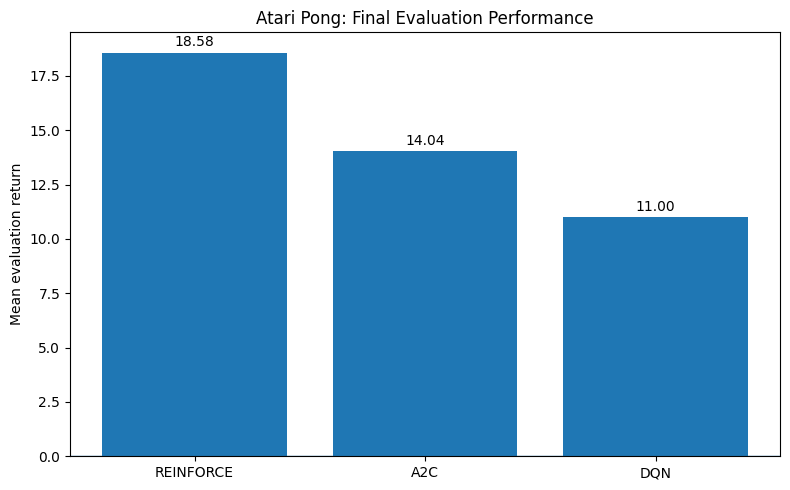

In [21]:
# ============================================================
# FIGURE 21.1
# FINAL EVALUATION PERFORMANCE
# ============================================================

plot_df = (
    COMPARISON_SUMMARY
    .set_index("algorithm")
    .reindex([
        "REINFORCE",
        "A2C",
        "DQN",
    ])
)


plt.figure(
    figsize=(8, 5)
)


bars = plt.bar(
    plot_df.index,
    plot_df["reported_eval_mean"],
)


plt.ylabel(
    "Mean evaluation return"
)

plt.title(
    "Atari Pong: Final Evaluation Performance"
)

plt.axhline(
    0,
    linewidth=1,
)


for bar, value in zip(
    bars,
    plot_df["reported_eval_mean"],
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{value:.2f}",
        ha="center",
    )


plt.tight_layout()


plt.savefig(
    FIGURES / "final_evaluation_performance.png",
    dpi=180,
)


plt.show()

### 21.2 Training Return vs Evaluation Return

This figure compares each algorithm's late-training performance with its final evaluation performance.

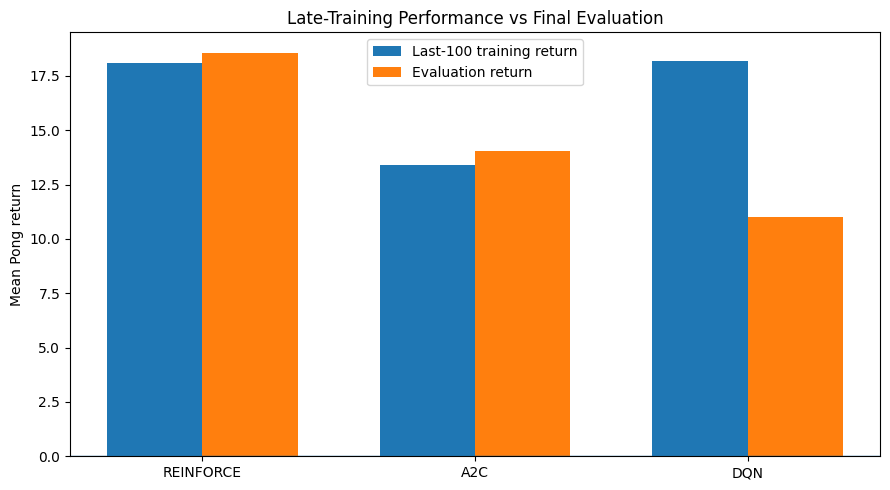

In [22]:
# ============================================================
# FIGURE 21.2
# TRAINING VS EVALUATION PERFORMANCE
# ============================================================

plot_df = (
    COMPARISON_SUMMARY
    .set_index("algorithm")
    .reindex([
        "REINFORCE",
        "A2C",
        "DQN",
    ])
)


x = np.arange(
    len(plot_df)
)

width = 0.35


plt.figure(
    figsize=(9, 5)
)


plt.bar(
    x - width / 2,
    plot_df["last100_mean"],
    width,
    label="Last-100 training return",
)


plt.bar(
    x + width / 2,
    plot_df["reported_eval_mean"],
    width,
    label="Evaluation return",
)


plt.xticks(
    x,
    plot_df.index,
)


plt.ylabel(
    "Mean Pong return"
)

plt.title(
    "Late-Training Performance vs Final Evaluation"
)

plt.axhline(
    0,
    linewidth=1,
)

plt.legend()

plt.tight_layout()


plt.savefig(
    FIGURES / "training_vs_evaluation.png",
    dpi=180,
)


plt.show()

### 21.3 Learning Progress vs Training Samples

This figure shows how REINFORCE and A2C performance changed as they consumed more environment interactions. The plotted value is the rolling mean return over the most recent 100 training episodes.

REINFORCE columns: ['episode', 'agent_steps', 'train_seconds', 'reward', 'mean100', 'full100', 'episode_length']
A2C columns: ['episode', 'agent_steps', 'train_seconds', 'reward', 'mean100', 'episode_length']


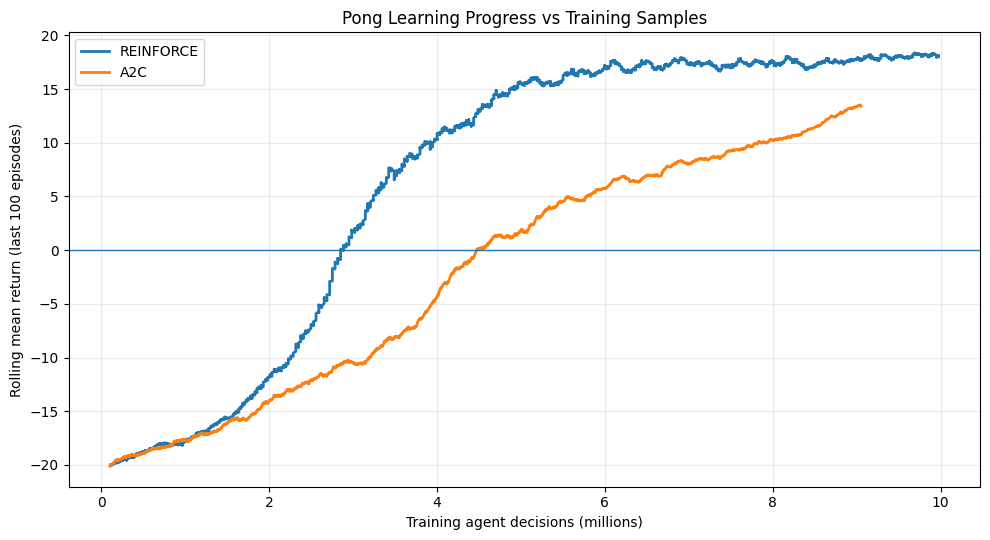

In [30]:
# ============================================================
# FIGURE 21.3
# LEARNING PROGRESS VS TRAINING SAMPLES
# ============================================================

reinforce_validation_file = (
    ROOT / "reinforce_longrun_validation.json"
)

a2c_validation_file = (
    ROOT / "a2c_longrun_validation.json"
)


assert reinforce_validation_file.exists(), (
    "Missing reinforce_longrun_validation.json"
)

assert a2c_validation_file.exists(), (
    "Missing a2c_longrun_validation.json"
)


reinforce_saved = json.loads(
    reinforce_validation_file.read_text()
)

a2c_saved = json.loads(
    a2c_validation_file.read_text()
)


# ============================================================
# LOCATE TRAINING HISTORIES
# ============================================================

reinforce_run_dir = Path(
    reinforce_saved["summary"]["run_dir"]
)

a2c_run_dir = Path(
    a2c_saved["summary"]["run_dir"]
)


reinforce_episodes_path = (
    reinforce_run_dir / "episodes.csv"
)

a2c_episodes_path = (
    a2c_run_dir / "episodes.csv"
)


assert reinforce_episodes_path.exists(), (
    f"Missing: {reinforce_episodes_path}"
)

assert a2c_episodes_path.exists(), (
    f"Missing: {a2c_episodes_path}"
)


reinforce_curve = pd.read_csv(
    reinforce_episodes_path
)

a2c_curve = pd.read_csv(
    a2c_episodes_path
)


print(
    "REINFORCE columns:",
    list(reinforce_curve.columns)
)

print(
    "A2C columns:",
    list(a2c_curve.columns)
)


# ============================================================
# BUILD A TRUE 100-EPISODE ROLLING MEAN
# ============================================================

def prepare_learning_curve(df):

    df = df.copy()

    df = df.sort_values(
        "agent_steps"
    ).reset_index(drop=True)


    # Find the episode reward column.
    if "reward" in df.columns:

        reward_col = "reward"

    elif "episode_return" in df.columns:

        reward_col = "episode_return"

    elif "return" in df.columns:

        reward_col = "return"

    else:

        raise KeyError(
            "Could not find episode reward column. "
            f"Available columns: {list(df.columns)}"
        )


    # Calculate the rolling mean ourselves.
    # min_periods=100 means the curve starts only after
    # 100 complete episodes exist.
    df["rolling100"] = (
        df[reward_col]
        .rolling(
            window=100,
            min_periods=100,
        )
        .mean()
    )


    # Remove the first 99 episodes.
    df = df[
        df["rolling100"].notna()
    ].copy()


    df["steps_millions"] = (
        df["agent_steps"]
        / 1_000_000.0
    )


    return df


reinforce_curve = prepare_learning_curve(
    reinforce_curve
)

a2c_curve = prepare_learning_curve(
    a2c_curve
)


# ============================================================
# PLOT
# ============================================================

plt.figure(
    figsize=(10, 5.5)
)


plt.plot(
    reinforce_curve["steps_millions"],
    reinforce_curve["rolling100"],
    label="REINFORCE",
    linewidth=2,
)


plt.plot(
    a2c_curve["steps_millions"],
    a2c_curve["rolling100"],
    label="A2C",
    linewidth=2,
)


plt.axhline(
    0,
    linewidth=1,
)


plt.xlabel(
    "Training agent decisions (millions)"
)

plt.ylabel(
    "Rolling mean return (last 100 episodes)"
)

plt.title(
    "Pong Learning Progress vs Training Samples"
)


plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    FIGURES
    / "learning_progress_vs_samples.png",
    dpi=180,
)


plt.show()

### 21.4 Learning Progress vs Wall-Clock Training Time

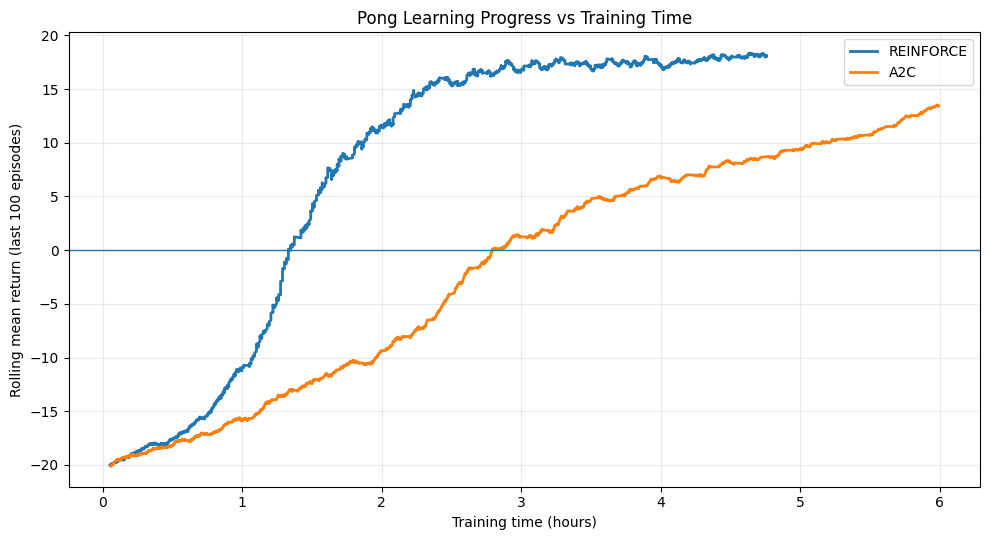

In [31]:
# ============================================================
# FIGURE 21.4
# LEARNING PROGRESS VS WALL-CLOCK TIME
# ============================================================

assert len(reinforce_curve) > 0, (
    "REINFORCE training history is empty."
)

assert len(a2c_curve) > 0, (
    "A2C training history is empty."
)


# Convert seconds to hours.
reinforce_curve[
    "training_hours"
] = (
    reinforce_curve["train_seconds"]
    / 3600.0
)

a2c_curve[
    "training_hours"
] = (
    a2c_curve["train_seconds"]
    / 3600.0
)


plt.figure(
    figsize=(10, 5.5)
)


plt.plot(
    reinforce_curve["training_hours"],
    reinforce_curve["rolling100"],
    label="REINFORCE",
    linewidth=2,
)


plt.plot(
    a2c_curve["training_hours"],
    a2c_curve["rolling100"],
    label="A2C",
    linewidth=2,
)


plt.axhline(
    0,
    linewidth=1,
)


plt.xlabel(
    "Training time (hours)"
)

plt.ylabel(
    "Rolling mean return (last 100 episodes)"
)

plt.title(
    "Pong Learning Progress vs Training Time"
)


plt.legend()

plt.grid(
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    FIGURES
    / "learning_progress_vs_time.png",
    dpi=180,
)


plt.show()

### 21.5 A2C Critic Learning Progress

This figure shows how the A2C critic's explained variance changed during training. Higher explained variance indicates that the learned value function is better able to explain variation in the return targets.

A2C update columns:
['update', 'agent_steps', 'episodes', 'train_seconds', 'mean100', 'baseline_weight', 'actor_entropy', 'actor_grad_norm', 'critic_loss', 'critic_grad_norm', 'explained_variance', 'best_eval', 'eval_mean', 'eval_std']


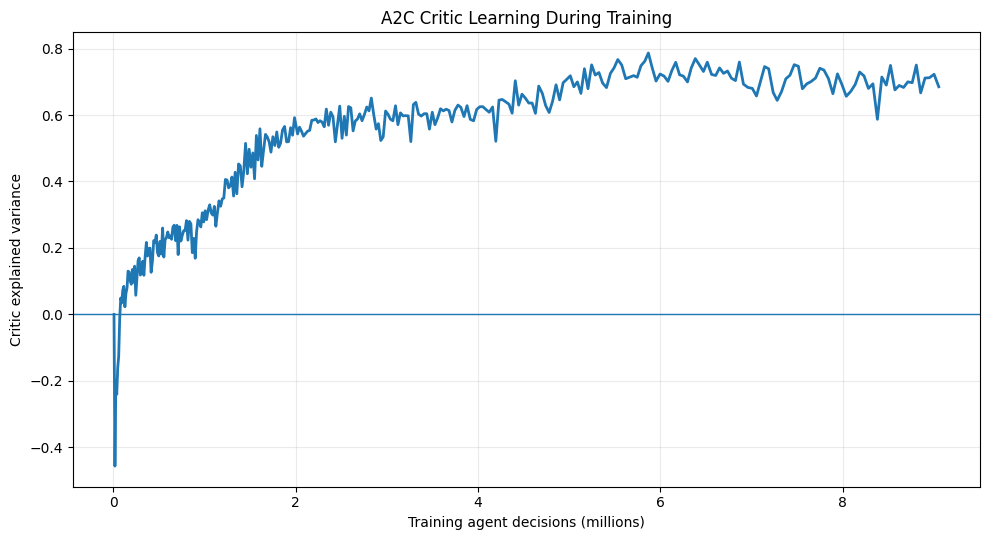

In [32]:
# ============================================================
# FIGURE 21.5
# A2C CRITIC LEARNING PROGRESS
# ============================================================

a2c_updates_path = (
    a2c_run_dir
    / "updates.csv"
)


assert a2c_updates_path.exists(), (
    f"Missing: {a2c_updates_path}"
)


a2c_updates_curve = pd.read_csv(
    a2c_updates_path
)


print(
    "A2C update columns:"
)

print(
    list(a2c_updates_curve.columns)
)


# Find the explained-variance column used by the trainer.
if "explained_variance" in a2c_updates_curve.columns:
    ev_col = "explained_variance"

elif "critic_explained_variance" in a2c_updates_curve.columns:
    ev_col = "critic_explained_variance"

elif "EV" in a2c_updates_curve.columns:
    ev_col = "EV"

else:
    raise KeyError(
        "Could not find the explained-variance column. "
        f"Available columns: {list(a2c_updates_curve.columns)}"
    )


a2c_updates_curve[
    "steps_millions"
] = (
    a2c_updates_curve["agent_steps"]
    / 1_000_000.0
)


plt.figure(
    figsize=(10, 5.5)
)


plt.plot(
    a2c_updates_curve["steps_millions"],
    a2c_updates_curve[ev_col],
    linewidth=2,
)


plt.axhline(
    0,
    linewidth=1,
)


plt.xlabel(
    "Training agent decisions (millions)"
)

plt.ylabel(
    "Critic explained variance"
)

plt.title(
    "A2C Critic Learning During Training"
)


plt.grid(
    alpha=0.25
)

plt.tight_layout()


plt.savefig(
    FIGURES
    / "a2c_critic_learning.png",
    dpi=180,
)


plt.show()

### 21.6 Individual Agent Evaluation Results

This figure shows the two Project 2 validation agents alongside each individual Project 1 DQN seed, making the variation between independently trained DQN agents visible.

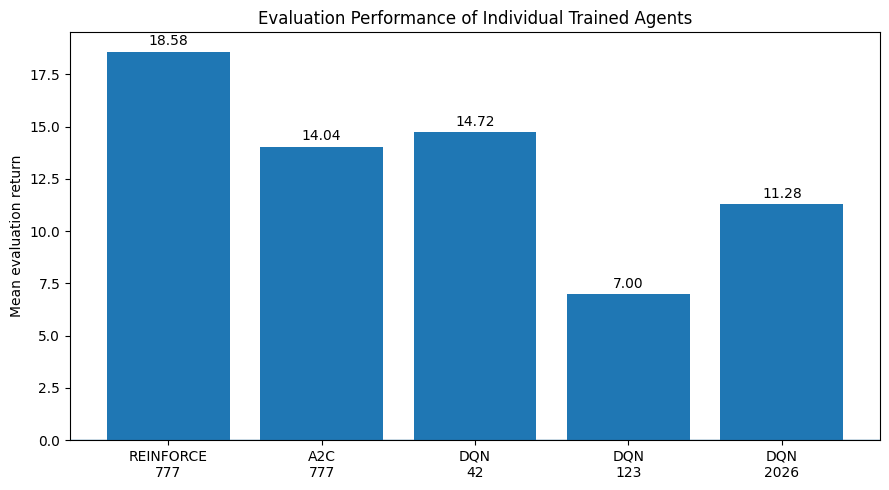

In [33]:
# ============================================================
# FIGURE 21.6
# INDIVIDUAL TRAINED AGENT PERFORMANCE
# ============================================================

labels = [
    "REINFORCE\n777",
    "A2C\n777",
    "DQN\n42",
    "DQN\n123",
    "DQN\n2026",
]


values = [
    REINFORCE_VALIDATION[
        "eval_mean"
    ],

    A2C_VALIDATION[
        "eval_mean"
    ],

    float(
        PROJECT1_DQN_BASELINE.loc[
            PROJECT1_DQN_BASELINE["seed"] == 42,
            "eval_mean",
        ].iloc[0]
    ),

    float(
        PROJECT1_DQN_BASELINE.loc[
            PROJECT1_DQN_BASELINE["seed"] == 123,
            "eval_mean",
        ].iloc[0]
    ),

    float(
        PROJECT1_DQN_BASELINE.loc[
            PROJECT1_DQN_BASELINE["seed"] == 2026,
            "eval_mean",
        ].iloc[0]
    ),
]


plt.figure(
    figsize=(9, 5)
)


bars = plt.bar(
    labels,
    values,
)


for bar, value in zip(
    bars,
    values,
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.3,
        f"{value:.2f}",
        ha="center",
    )


plt.ylabel(
    "Mean evaluation return"
)

plt.title(
    "Evaluation Performance of Individual Trained Agents"
)

plt.axhline(
    0,
    linewidth=1,
)

plt.tight_layout()


plt.savefig(
    FIGURES / "individual_agent_performance.png",
    dpi=180,
)


plt.show()

### 21.7 Training Sample Usage on a Logarithmic Scale

Because DQN used far fewer environment decisions than REINFORCE and A2C, a logarithmic scale makes the sample-efficiency difference easier to visualize.

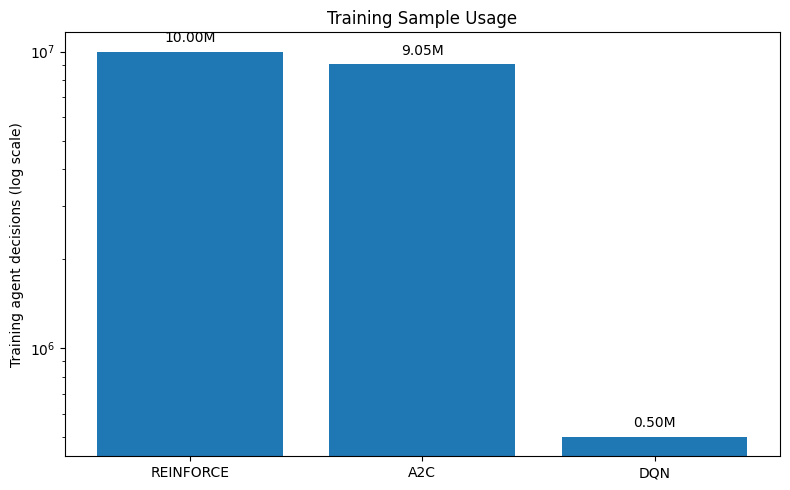

In [34]:
# ============================================================
# FIGURE 21.7
# SAMPLE USAGE — LOG SCALE
# ============================================================

plot_df = (
    COMPARISON_SUMMARY
    .set_index("algorithm")
    .reindex([
        "REINFORCE",
        "A2C",
        "DQN",
    ])
)


plt.figure(
    figsize=(8, 5)
)


bars = plt.bar(
    plot_df.index,
    plot_df[
        "agent_steps"
    ],
)


plt.yscale(
    "log"
)


plt.ylabel(
    "Training agent decisions (log scale)"
)

plt.title(
    "Training Sample Usage"
)


for bar, value in zip(
    bars,
    plot_df["agent_steps"],
):

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        value * 1.08,
        f"{value / 1_000_000:.2f}M",
        ha="center",
    )


plt.tight_layout()


plt.savefig(
    FIGURES / "sample_usage_log.png",
    dpi=180,
)


plt.show()

### 21.8 Figure Summary

The figures provide several complementary views of the measured Pong experiments:

- **Final Evaluation Performance** compares the final measured evaluation returns of REINFORCE, A2C, and DQN.
- **Training Return vs Evaluation Return** shows whether late-training performance was maintained during evaluation.
- **Learning Progress vs Training Samples** shows how REINFORCE and A2C improved as additional environment decisions were collected.
- **Learning Progress vs Wall-Clock Training Time** shows how quickly each policy-gradient method improved in terms of actual computational time.
- **A2C Critic Learning Progress** tracks the critic's explained variance and shows whether the learned value function became more predictive during training.
- **Individual Agent Evaluation Results** displays REINFORCE and A2C alongside each of the three independently trained DQN seeds, exposing the variability of the Project 1 DQN results.
- **Training Sample Usage on a Logarithmic Scale** highlights the substantially smaller number of environment interactions used by DQN relative to the two policy-gradient methods.

Together, these figures compare not only final performance but also convergence behavior, computational cost, sample usage, evaluation stability, and the contribution of the A2C critic.

## 22. Interpretation Notes for the Report

All conclusions below are based on the measured experimental results rather than expected or theoretical scores.

### Final Performance

REINFORCE achieved the strongest final evaluation result, with a mean return of **18.58** over 50 stochastic evaluation episodes. A2C achieved **14.04**, while the three Project 1 DQN runs produced an average evaluation return of **11.00**.

Therefore, for the measured experiments:

\[
\text{REINFORCE} > \text{A2C} > \text{DQN average}
\]

in final evaluation return.

### REINFORCE

REINFORCE is an on-policy Monte Carlo policy-gradient method. The implementation collects complete Pong episodes, computes point-boundary discounted returns, normalizes the return signal within each complete episode, and accumulates policy gradients across complete games.

The final REINFORCE model achieved:

- **10,000,000 agent decisions**
- **18.11 last-100 training return**
- **18.58 final evaluation mean**
- **2.18 evaluation episode standard deviation**
- approximately **4.77 hours of training**

The training and evaluation scores were very similar, indicating that the strong late-training behavior was also maintained during evaluation.

### A2C

A2C is also on-policy but introduces a learned state-value critic \(V(s)\). The final actor advantage is computed as

\[
A_t = G_t - \beta V(s_t)
\]

where \(G_t\) is the point-boundary discounted return.

The critic contribution coefficient \(\beta\) begins at zero and gradually increases to one. This allows the actor to initially receive a policy-gradient signal close to REINFORCE while the critic learns in parallel.

The final A2C model achieved:

- **9,050,863 agent decisions**
- **13.41 last-100 training return**
- **14.04 final evaluation mean**
- **3.12 evaluation episode standard deviation**
- approximately **6.04 hours of training**

By the end of training, \(\beta=1.0\), meaning the learned critic was fully participating in the actor advantage. The critic's explained variance reached approximately **0.72** near the end of training, showing that it had learned a meaningful prediction of the return targets.

The A2C learning curves also show that the method improved steadily from poor initial Pong performance into positive returns. However, in this experiment it converged more slowly and reached a lower final score than REINFORCE.

### DQN

DQN is fundamentally different because it is an off-policy value-based algorithm. It reuses previous transitions through experience replay and learns bootstrapped action-value estimates.

The three Project 1 DQN evaluation results were:

- seed 42: **14.72**
- seed 123: **7.00**
- seed 2026: **11.28**

Their average evaluation return was **11.00**, despite late-training returns averaging approximately **18.20**.

This creates a substantially larger training-to-evaluation difference than was observed for REINFORCE or A2C. It also demonstrates considerable variation across independently trained DQN seeds.

DQN used only **500,000 agent decisions per training run**, substantially fewer than REINFORCE or A2C. Therefore, although its mean final evaluation score was lower, DQN was considerably more sample-efficient in terms of environment interaction.

### Convergence and Sample Efficiency

The learning-curve plots provide a more informative comparison than final scores alone.

REINFORCE and A2C initially performed poorly and required millions of agent decisions before reaching strong positive Pong returns. REINFORCE ultimately learned the stronger policy and also completed its long-run experiment in less wall-clock time than A2C.

DQN required far fewer environment interactions, although the Project 1 results also showed substantial sensitivity to training seed and a larger difference between late-training and evaluation performance.

The experiments therefore demonstrate a tradeoff:

- **REINFORCE** produced the highest final performance.
- **A2C** successfully learned a useful actor and critic but did not outperform REINFORCE in this implementation.
- **DQN** used dramatically fewer environment interactions but produced lower and more seed-sensitive evaluation performance.

### Bias and Value Estimation

REINFORCE uses Monte Carlo returns and does not bootstrap from a learned value estimate. This avoids bootstrap bias but produces higher-variance gradient estimates.

A2C learns a critic to estimate the value function. The critic can reduce policy-gradient variance but introduces error and bias when its value estimates are inaccurate. The increasing explained variance observed during training indicates that the final critic became substantially more predictive.

DQN uses bootstrapped Q-learning targets and selects actions using maximum estimated action values. This can produce positive Q-value overestimation when noisy value estimates are maximized.

### On-Policy vs Off-Policy Learning

REINFORCE and A2C are **on-policy**. Experience collected under older policies is not repeatedly reused for later actor updates.

DQN is **off-policy**. Replay-buffer transitions can be sampled many times, allowing substantially greater data reuse and helping explain its lower environment-interaction requirement.

### Experimental Limitations

REINFORCE and A2C use the two meaningful Pong movement actions, LEFT and RIGHT, after FIRE reset. Project 1 DQN used the complete six-action Pong action space.

The evaluation protocols also differ: DQN used an epsilon-\(0.02\) evaluation policy, while REINFORCE and A2C were evaluated using their learned stochastic policies.

Finally, REINFORCE and A2C each use one completed seed-777 long-run validation experiment, whereas DQN has three independently trained seeds. Therefore, equivalent across-seed statistical confidence is not claimed for all three algorithms.

The standard deviations reported for REINFORCE and A2C describe variation across evaluation episodes of one trained model and should not be interpreted as variation across independently trained seeds.

## 23. Final Experimental Summary

This project implemented and evaluated REINFORCE and an advantage actor-critic method on Atari Pong while preserving the environment and preprocessing pipeline used in Project 1. The completed Project 1 DQN results were reused as the off-policy comparison baseline.

The final measured results were:

| Algorithm | Evaluation Return | Training Decisions | Training Time |
|---|---:|---:|---:|
| REINFORCE | **18.58 ± 2.18** | **10.00M** | **4.77 h** |
| A2C | **14.04 ± 3.12** | **9.05M** | **6.04 h** |
| DQN | **11.00 average** | **0.50M per run** | **1.20 h average** |

REINFORCE achieved the highest final evaluation performance and reached a last-100 training return of **18.11**. Its final evaluation mean of **18.58** was very close to its late-training performance, indicating a small training-to-evaluation difference.

A2C also learned successfully. Its final last-100 training return reached **13.41**, and the final 50-episode stochastic evaluation produced a mean return of **14.04**. The A2C critic reached an explained variance of approximately **0.72** near the end of training, providing evidence that the value network learned a meaningful baseline for the actor. Nevertheless, the additional critic did not cause A2C to outperform REINFORCE in this particular Pong implementation.

DQN used dramatically fewer environment interactions than either policy-gradient method. Each Project 1 DQN run used only **500,000 agent decisions**, demonstrating substantially greater sample efficiency. However, its evaluation performance varied considerably across training seeds, with scores of **14.72**, **7.00**, and **11.28** for seeds 42, 123, and 2026 respectively.

The experiments therefore reveal that no single algorithm dominated every metric. **REINFORCE produced the strongest final Pong policy, DQN required the fewest environment interactions, and A2C demonstrated successful actor-critic learning with a meaningful learned value function but required the greatest wall-clock training time.**

The results also highlight an important reinforcement-learning lesson: adding a critic does not automatically guarantee better performance than a simpler policy-gradient method. Algorithm behavior depends strongly on representation, credit assignment, optimization, hyperparameters, environment dynamics, and the available training budget.

Overall, the measured results support the following experimental ranking:

- **Best final evaluation performance:** REINFORCE
- **Best sample efficiency:** DQN
- **Successful learned value baseline:** A2C
- **Lowest measured policy-gradient training time:** REINFORCE
- **Largest observed training-seed variability:** DQN

These conclusions are specific to the measured Atari Pong experiments and should not be interpreted as universal rankings of REINFORCE, A2C, and DQN.